In [2]:
"""
Quick-start example — replace PATH and orbit numbers as needed.
"""

%reload_ext autoreload
%autoreload 2

from core.data_loader  import SimulationDataLoader
from core.variables    import SimulationVariablesCalculator
from core.streamlines  import SimulationDataStreamlines
from core.processor    import SimulationDataProcessor
from analysis.orbital_evolution import da_dt_calculator
from analysis.stokes   import relative_velocity_calculator, Stokes_from_Particle
from analysis.fft_analysis import FFT_1D_Analyzer
from utils.visualization   import animate_dust_gas
from get_parameters import read_par

PATH  = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_nooutbc_v5/'
ORBIT = 20
DUST  = 1


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import random

from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "astro_blue",
    [
        "#000000",  # black
        "#0a0f2a",  # very dark blue
        "#162a5c",  # deep blue
        "#2b5da8",  # medium blue
        "#4fa3d9",  # cyan-ish
        "#a6d5e3",  # light cyan
        "#f2f2f2"   # near white
    ]
)

cmap_dust = LinearSegmentedColormap.from_list(
    "astro_orange",
    [
        "#000000",  # black
        "#2a150a",  # very dark brown-orange
        "#5c2e16",  # deep burnt orange
        "#a85a2b",  # medium orange
        "#d98f4f",  # warm orange
        "#e3c5a6",  # light peach
        "#f2f2f2"   # near white
    ]
)

particle
Stokes number range: 0.004959859887356251 - 11480859.514407177
71
particle
Stokes number range: 0.04968223870620463 - 114808568.46094644
61
particle
Stokes number range: 0.4999734785799418 - 1148086175.0269914
64
particle
Stokes number range: 4.986471858130613 - 11480857501.677732
175


c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\stokes.py:244: RuntimeWarning: invalid value encountered in sqrt
  beta      = np.sqrt(1 + 2 * eta)
C:\Users\david\AppData\Local\Temp\ipykernel_23500\2555547415.py:70: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(X, Y, np.log10(dustdens), cmap=cmap, vmin = -10, vmax = -6)


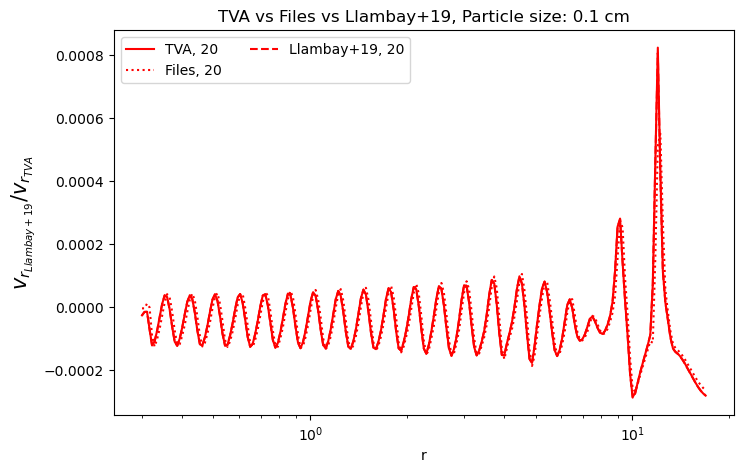

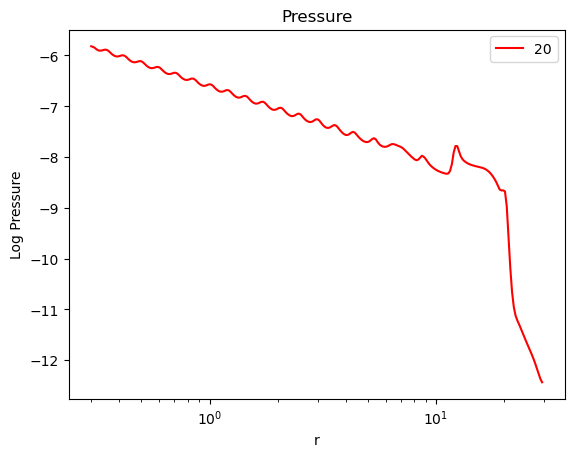

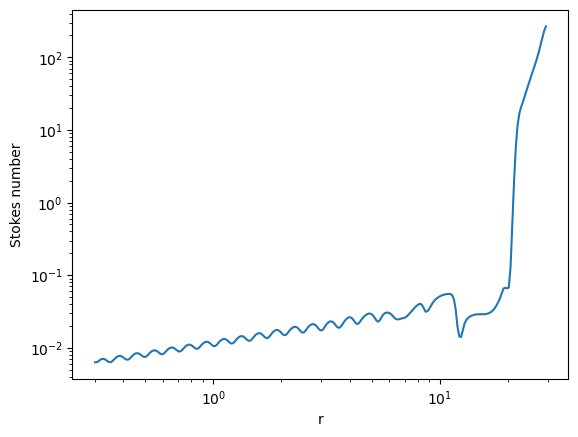

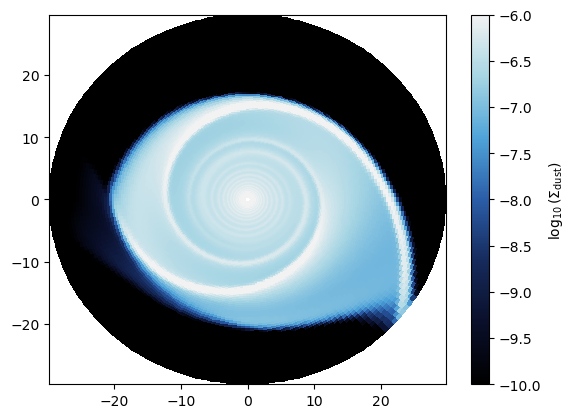

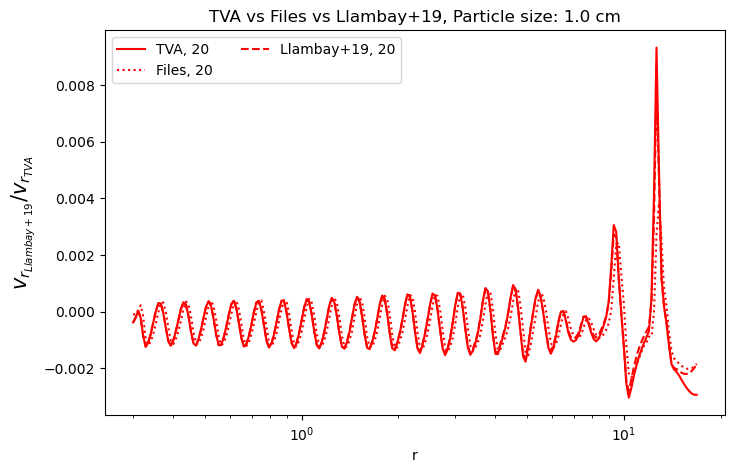

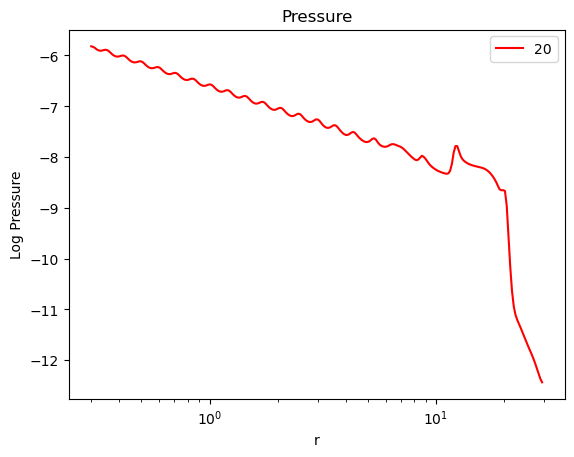

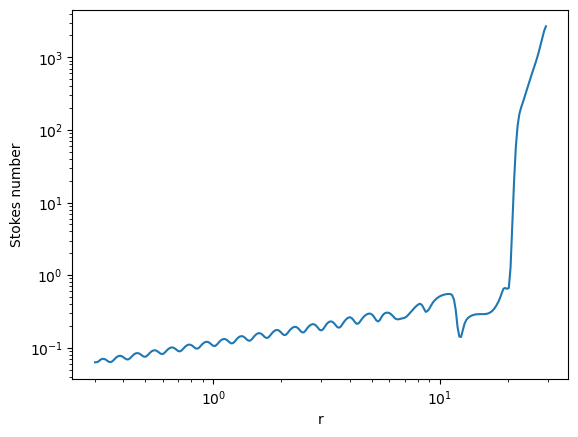

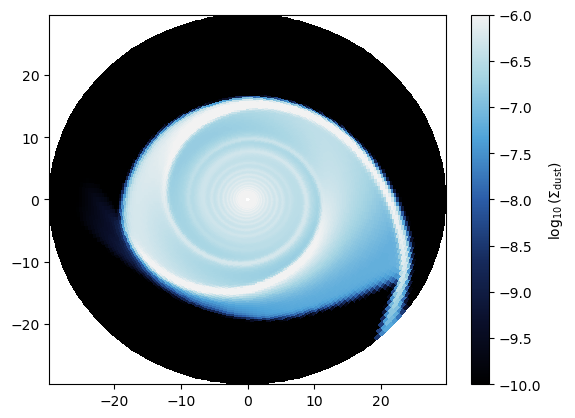

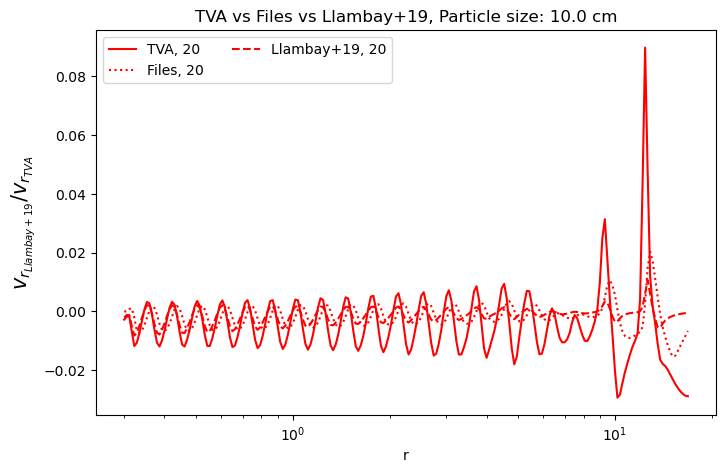

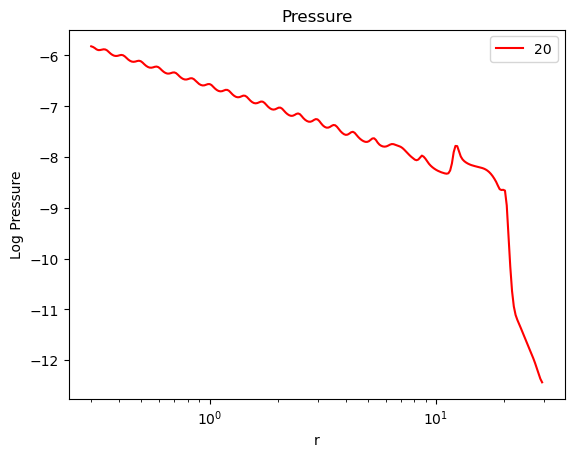

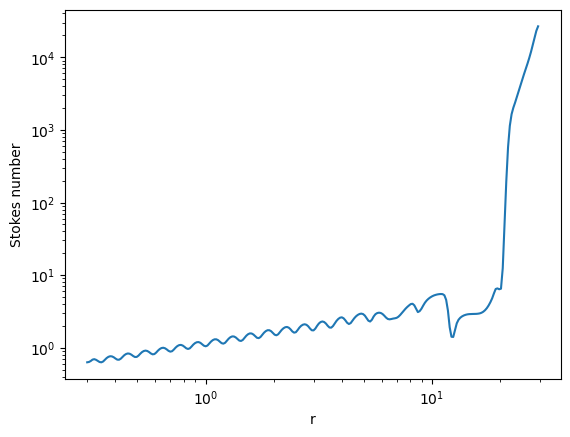

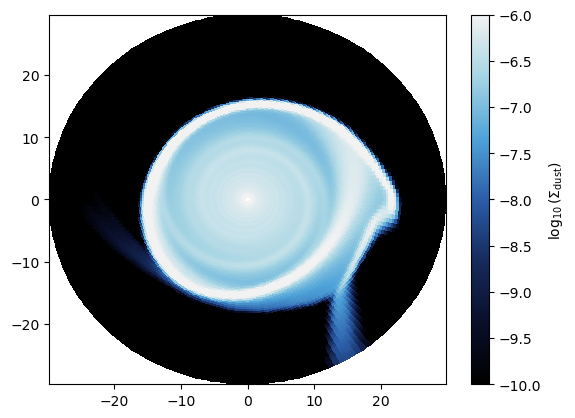

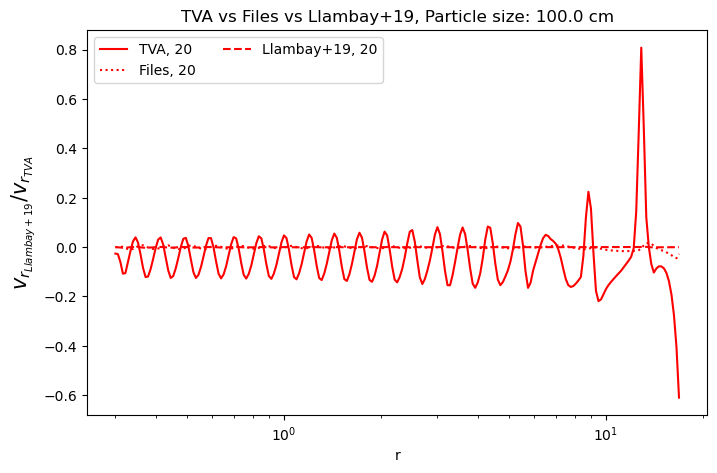

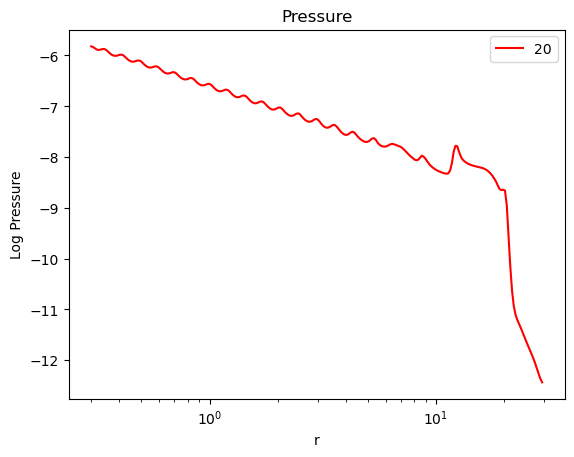

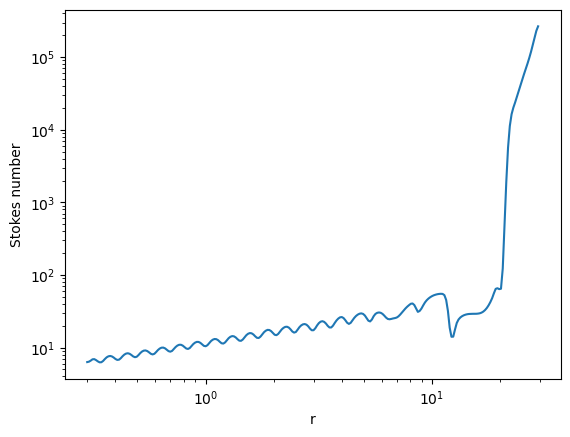

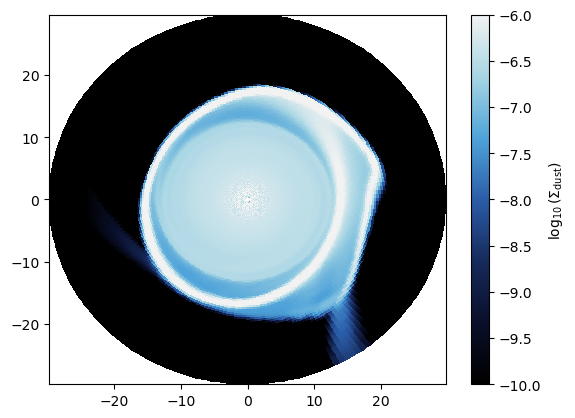

In [7]:
%reload_ext autoreload
%autoreload 2
def relative_vel(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    rvc = relative_velocity_calculator(loader, variables, DUST, 1, '')

    vr_fargo_sim = rvc.calculate_relative_velocity(orbit)
    print(particle_type)
    
    vr_TVA = rvc.TVA(orbit, path, particle_type)

    vr_llambay, St = rvc.llambay_19(orbit, path, particle_type)

    params = read_par(path)

    #St = 1/float(params['INVSTOKES1'])
    particle_size = float(params['PARTICLESIZE1'])

    

    phi_grid = np.loadtxt(path + 'domain_x.dat')[:-1]
    r_grid = np.loadtxt(path + 'domain_y.dat')[3:-4]
    X, Y = loader.X, loader.Y

    cmap_lines = plt.cm.rainbow

    color = cmap_lines(orbit/20)

    pressure = variables.calculate_gas_pressure(orbit)[:, 0]
    presax.plot(r_grid, np.log10(pressure), color = color, label=rf'{orbit}')
    presax.set_xscale('log')
    presax.set_ylabel('Log Pressure')
    presax.set_xlabel('r')
    presax.set_title(f'Pressure')
    presax.legend(ncols = 2)


    mask = r_grid < 17
    phi_idx = random.randint(0, len(phi_grid) - 1)
    #phi_idx = 75
    print(phi_idx)
    vr_profile = vr_TVA[:, phi_idx]
    vr_sim_profile = vr_fargo_sim[:, phi_idx]
    vr_llambay = vr_llambay[:, phi_idx]

    
    #ax3.plot(r_grid[mask], np.log10(-vr_profile[mask]), color = cmap_lines(orbit/max(orbits)), label=rf'TVA, {orbit}')
    #ax3.plot(r_grid[mask], np.log10(-vr_sim_profile[mask]), ':', color=cmap_lines(orbit/max(orbits)), label=rf'Files, {orbit}')
    #ax3.plot(r_grid[mask], np.log10(-vr_llambay[mask]), '--', color=cmap_lines(orbit/max(orbits)), label=rf'Llambay+19, {orbit}')

    ax3.plot(r_grid[mask], (vr_profile[mask]), color = color, label=rf'TVA, {orbit}')
    ax3.plot(r_grid[mask], (vr_sim_profile[mask]), ':', color=color, label=rf'Files, {orbit}')
    ax3.plot(r_grid[mask], (vr_llambay[mask]), '--', color=color, label=rf'Llambay+19, {orbit}')

    #ax3.plot(r_grid[mask], (vr_llambay[mask]/vr_profile[mask]), '-.', color=color, label=rf'Llambay+19/TVA, {orbit}')
    #ax3.plot(r_grid[mask], 1 / (1 + St[:, phi_idx][mask]**2), ':', color='blue', label=rf'1 / (1 + St^2), {orbit}')
    ax3.set_xlabel('r')
    #ax3.set_ylabel(r'$v_{r_{dust}} - v_{r_{gas}}$', fontsize = 15)
    ax3.set_ylabel(r'$v_{r_{Llambay+19}} / v_{r_{TVA}}$', fontsize = 15)
    #ax3.set_yscale('symlog', linthresh=1e-4)
    ax3.legend(ncol=2, fontsize=10)
    ax3.set_xscale('log')

    ax3.set_title(f'TVA vs Files vs Llambay+19, Particle size: {particle_size} cm')

    fig, ax = plt.subplots()
    dustdens = loader.load_dustdens(orbit, 1)
    gasdens = loader.load_gasdens(orbit)
    pcm = ax.pcolormesh(X, Y, np.log10(dustdens), cmap=cmap, vmin = -10, vmax = -6)
    cm = plt.colorbar(pcm, ax=ax, label=r'$\log_{10}(\Sigma_{\rm dust})$')
    


#Sts = [0.01, 0.1, 1, 10, 100]

Sts = [0.01]
orbits = np.arange(0, 21, 5)
orbits = np.linspace(0, 5, 5, dtype=int)
orbits = [20]
paths = [#f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_nooutbc_v5/',
         #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/', 
         #'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_bin/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_highres/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_St0.001/'
        ]

particles = ['particle', 'particle', 'particle', 'particle']

for i, path in enumerate(paths):
    fig3, ax3 = plt.subplots(1, 1, figsize=(8, 5))
    presfig, presax = plt.subplots(1, 1)
    for orbit in orbits:
        #orbit *= 4
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_single_dust_St{St}_nobin_lowvisc_contd/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_St{St}_nobin_powerlawbc_1d/'
        #path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_St0.01_eps0.01_v2/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_initial_walpha/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_3dust_bin/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_final_2d/'
        particle_type = particles[i]
        relative_vel(path, orbit)

In [70]:
from utils.constants import R0_CGS, MSTAR_CGS, MSTAR, R0

particle_size = 0.0001 * R0 / R0_CGS
rhosolid = 2.4 * R0_CGS**3 / MSTAR_CGS * MSTAR / R0**3
r = 1.496e13 * R0 / R0_CGS

h = 0.05 * r

cs = 0.05 * np.sqrt(1/r)
v_thermal = np.sqrt(8 / np.pi) * cs
Sigma = 1000 * R0_CGS**2 / MSTAR_CGS * MSTAR / R0**2# / (np.sqrt(2 * np.pi) * h)
stopping_time = (rhosolid * particle_size) / (Sigma * v_thermal)
St = stopping_time * np.sqrt(1 / r**3)
print(St)

1.5641137837064003e-05


In [71]:
import math
R0 = 5.2
R0_CGS = 5.2*1.496*10**13
MSTAR_CGS = 1.9891*10**33
MSTAR = 1
R0 = 1
particle_size = 1*R0/R0_CGS
rhosolid = 2.4*R0_CGS**3/MSTAR_CGS
r = 1.496*10**13*R0/R0_CGS
h = 0.05*r
cs = 0.05*np.sqrt(1/r)
v_thermal = np.sqrt(8/np.pi)*cs
Sigma = 1000*R0_CGS**2/MSTAR_CGS
rho_gas = Sigma/(h*math.sqrt(2*math.pi))
stopping_time = (rhosolid*particle_size)/(rho_gas*v_thermal)
St = stopping_time*np.sqrt(1/r**3)
print(St)

0.0037699111843077513


non-axisymmetric
Stokes number range: 0.04968223870620463 - 114808568.46094644


C:\Users\david\AppData\Local\Temp\ipykernel_28624\3442010850.py:37: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)


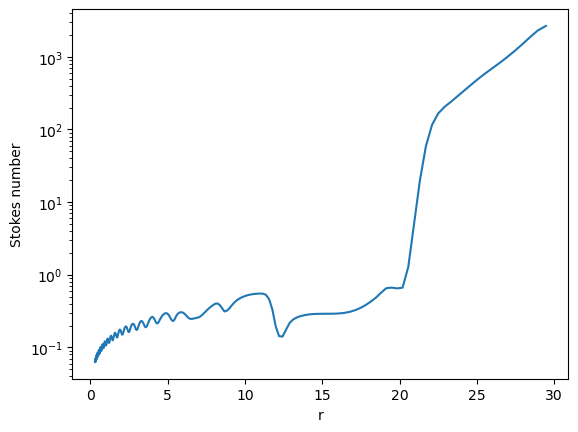

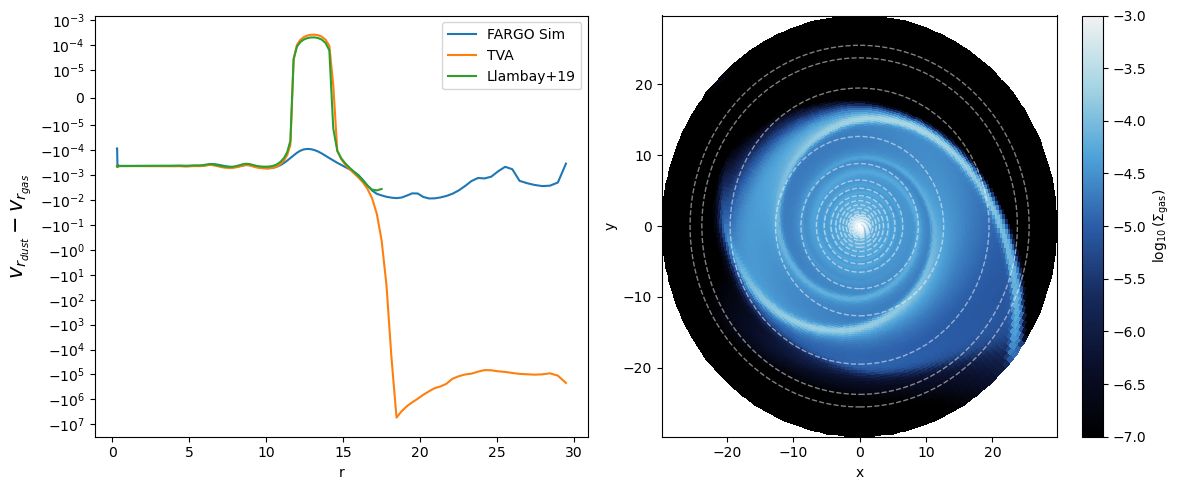

In [5]:
%reload_ext autoreload
%autoreload 2

def axisymmetric_avg(data):
    return np.mean(data, axis=1)


def axisymmetric_relative_vel(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    rvc = relative_velocity_calculator(loader, variables, DUST, '')

    vr_fargo_sim = rvc.calculate_relative_velocity(orbit)
    particle_type = 'particle'
    vr_TVA = rvc.TVA(orbit, path, particle_type)
    vr_llambay = rvc.llambay_19(orbit, path, particle_type)

    r_grid = loader.r_grid

    vr_sim_avg = axisymmetric_avg(vr_fargo_sim)
    vr_TVA_avg = axisymmetric_avg(vr_TVA)
    vr_llambay_avg = axisymmetric_avg(vr_llambay)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(r_grid, vr_sim_avg, label='FARGO Sim')
    ax[0].plot(r_grid, vr_TVA_avg, label='TVA')
    ax[0].plot(r_grid, vr_llambay_avg, label='Llambay+19')
    ax[0].set_xlabel('r')
    ax[0].set_ylabel(r'$v_{r_{dust}} - v_{r_{gas}}$', fontsize= 15)
    ax[0].set_yscale('symlog', linthresh=1e-5)

    vr_sim_local_maxima = r_grid[(np.diff(np.sign(np.diff(vr_sim_avg))) < 0).nonzero()[0] + 1]


    gasdens = loader.load_gasdens(orbit)
    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
    #add circles in constant r where local maxima occur in vr_sim_avg
    for r in vr_sim_local_maxima:
        circle = plt.Circle((0, 0), r, color='white', fill=False, linestyle='--', alpha=0.5)
        ax[1].add_artist(circle)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[0].legend()
    plt.tight_layout()
    plt.show()

PATH  = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/'
ORBIT = 20
DUST  = 1

axisymmetric_relative_vel(PATH, ORBIT)

axisymmetric
Stokes number range: 0.06310294119121435 - 46.336007048179866
fargo_sim: max relative variation = 78.3595
TVA: max relative variation = 0.0000
llambay: max relative variation = 0.0000


C:\Users\david\AppData\Local\Temp\ipykernel_28624\3168680146.py:46: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gdens), cmap=cmap, vmin=-7, vmax=-3)


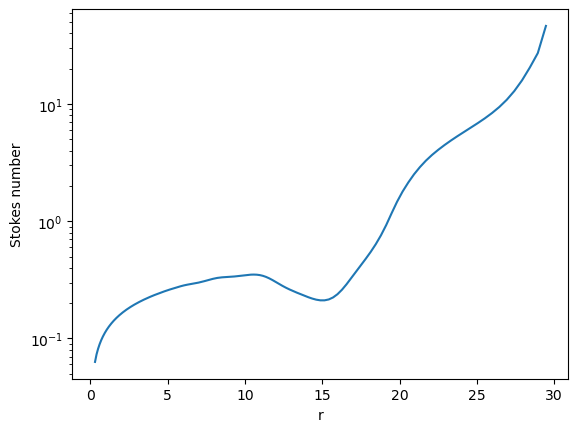

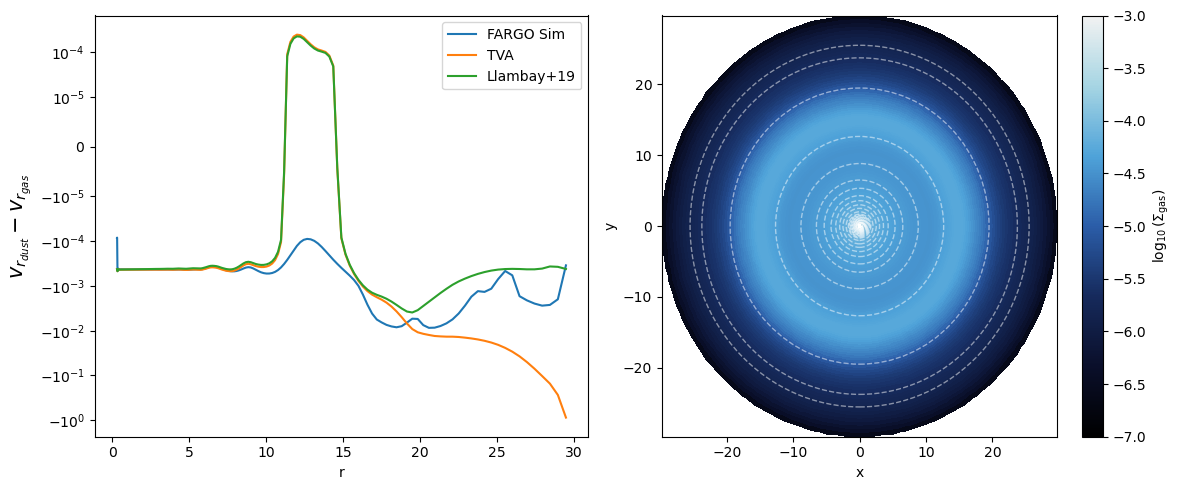

In [6]:
%reload_ext autoreload
%autoreload 2

def axisymmetric_relative_vel(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    rvc = relative_velocity_calculator(loader, variables, DUST, 'axisymmetric')

    vr_fargo_sim = rvc.calculate_relative_velocity(orbit)
    particle_type = 'particle'
    vr_TVA = rvc.TVA(orbit, path, particle_type)
    vr_llambay = rvc.llambay_19(orbit, path, particle_type)

    for name, arr in [('fargo_sim', vr_fargo_sim), ('TVA', vr_TVA), ('llambay', vr_llambay)]:
        std_phi  = np.std(arr, axis=1)   # std over phi, shape (nr,)
        mean_phi = np.mean(arr, axis=1)  # mean over phi, shape (nr,)
        rel_var  = std_phi / np.abs(mean_phi)
        print(f"{name}: max relative variation = {np.nanmax(rel_var):.4f}")

    r_grid = loader.r_grid

    vr_sim_avg = axisymmetric_avg(vr_fargo_sim)
    vr_TVA_avg = axisymmetric_avg(vr_TVA)
    vr_llambay_avg = axisymmetric_avg(vr_llambay)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    ax[0].plot(r_grid, vr_sim_avg, label='FARGO Sim')
    #ax[0].plot(r_grid, vr_TVA_avg, label='TVA')
    #ax[0].plot(r_grid, vr_llambay_avg, label='Llambay+19')
    
    #ax[0].plot(r_grid, vr_fargo_sim, label='FARGO Sim')
    ax[0].plot(r_grid, vr_TVA[:, 0], label='TVA')
    ax[0].plot(r_grid, vr_llambay[:, 0], label='Llambay+19')
    ax[0].set_xlabel('r')
    ax[0].set_ylabel(r'$v_{r_{dust}} - v_{r_{gas}}$', fontsize= 15)
    ax[0].set_yscale('symlog', linthresh=1e-5)

    vr_sim_local_maxima = r_grid[(np.diff(np.sign(np.diff(vr_sim_avg))) < 0).nonzero()[0] + 1]


    gasdens = np.mean(loader.load_gasdens(orbit), axis=1)
    gdens = np.zeros((len(loader.r_grid), len(loader.phi_grid)))
    for i in range(len(loader.r_grid)):
        gdens[i, :] = gasdens[i]
    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gdens), cmap=cmap, vmin=-7, vmax=-3)
    for r in vr_sim_local_maxima:
        circle = plt.Circle((0, 0), r, color='white', fill=False, linestyle='--', alpha=0.5)
        ax[1].add_artist(circle)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[0].legend()
    plt.tight_layout()
    plt.show()
particle_type = 'stokes'

PATH  = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/'
ORBIT = 20
DUST  = 1

axisymmetric_relative_vel(PATH, ORBIT)

C:\Users\david\AppData\Local\Temp\ipykernel_17092\4154822493.py:26: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_17092\4154822493.py:32: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap, vmin=-9, vmax=-5)


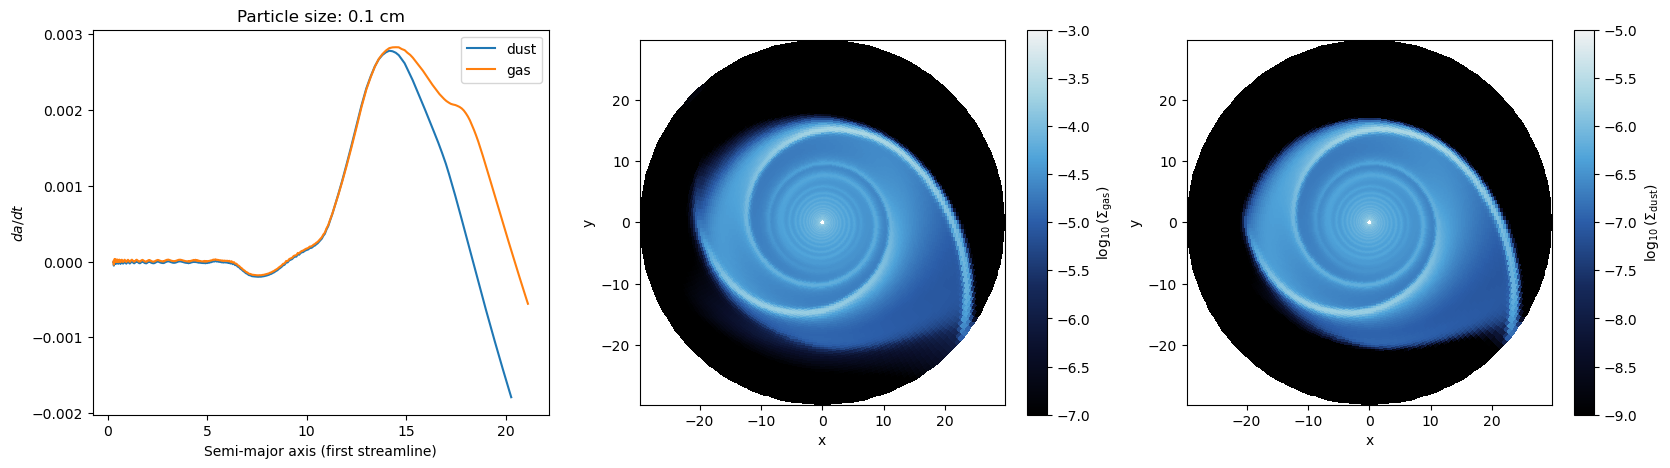

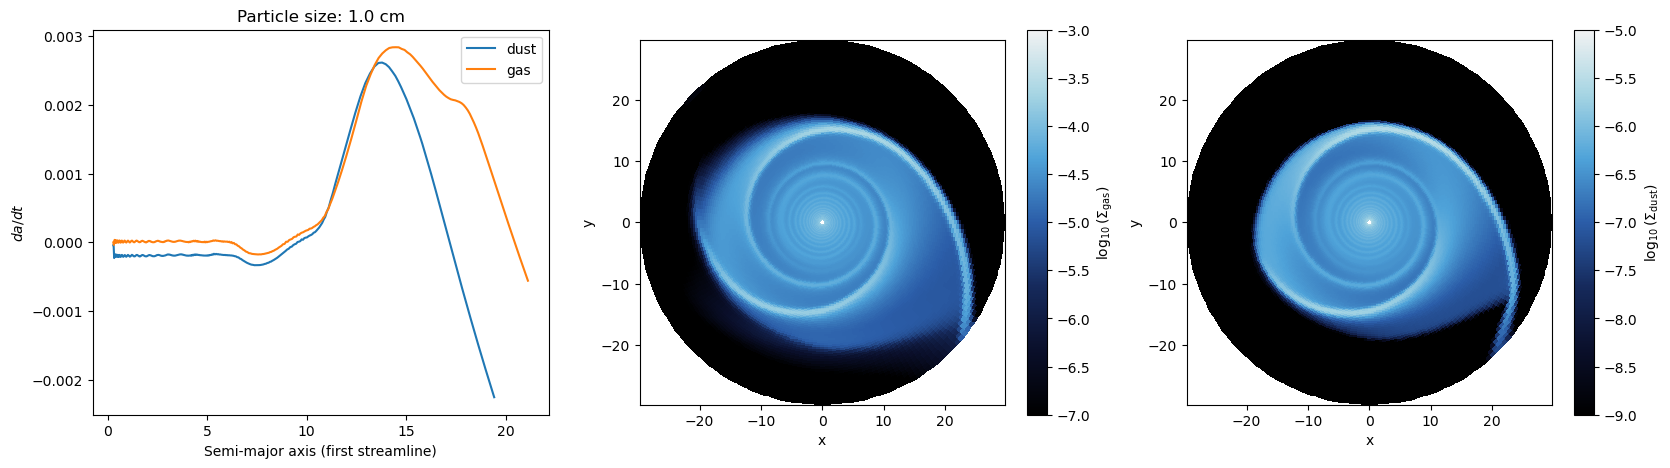

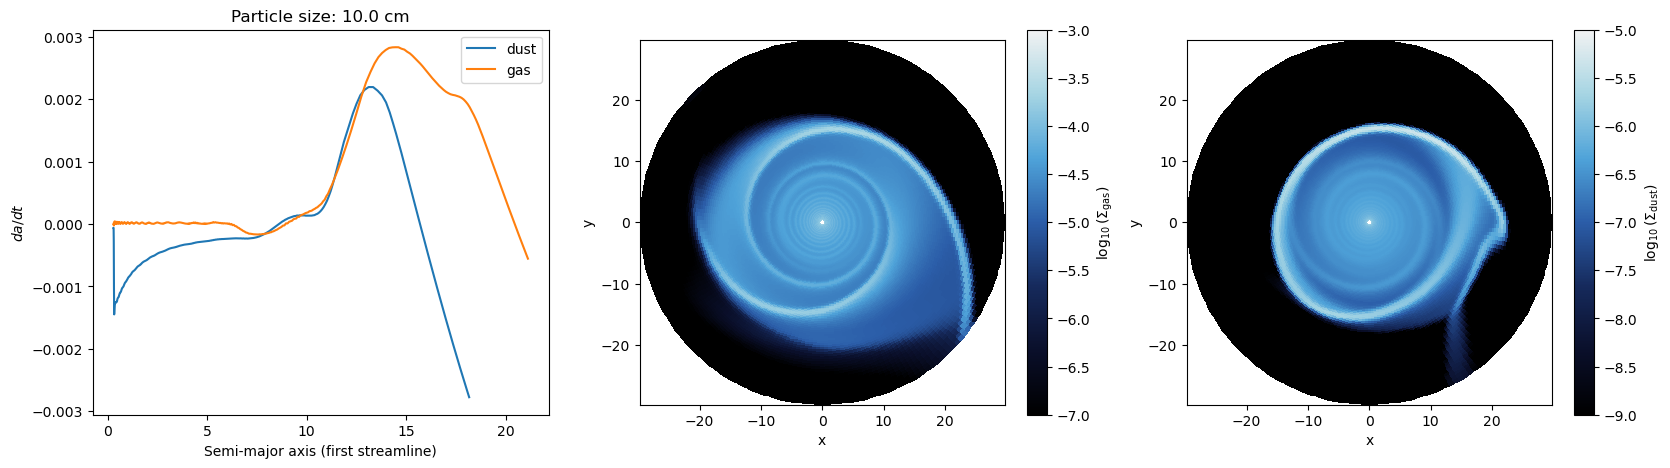

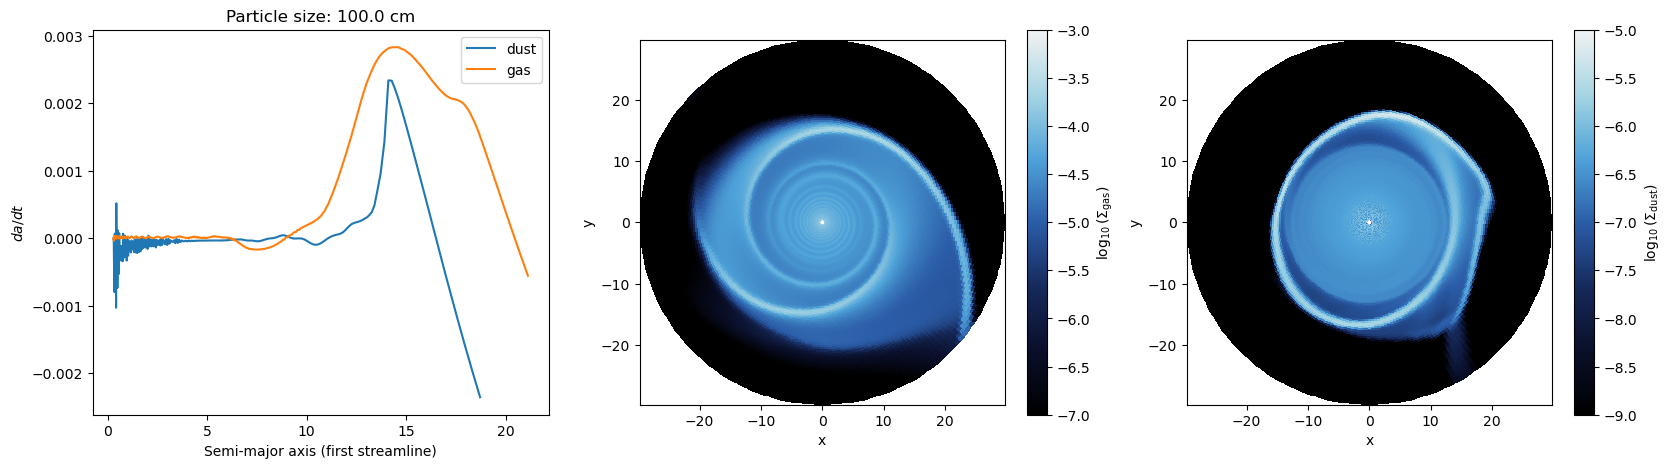

In [19]:
%reload_ext autoreload
%autoreload 2

def plot_da_dt(path, orbit, material, dust_num):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)


    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)


    ax[0].plot(a_array, da_dt_arr, label=rf'{material}')
    ax[0].set_xlabel('Semi-major axis (first streamline)')
    ax[0].set_ylabel(r'$da/dt$')
    #ax[0].set_yscale('log')
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)
        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x')
        ax[1].set_ylabel('y')
        ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap, vmin=-9, vmax=-5)
        cm = plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x')
        ax[2].set_ylabel('y')
        ax[2].set_aspect('equal')

PATH = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_nooutbc_v5/'

paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_St0.001/'
        ]

ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']
for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_da_dt(path, ORBIT, material, dust_num)

Use streamlines to calculate axisymmetric density (average over fixed a) to input into TVA

Terminal Velocity Approximation:

$\Delta v_r = \frac{\tau_{\rm stop}}{\Sigma}\nabla P$

where 

$P = c_s^2 \Sigma$

$\tau_{\rm stop} = St/\Omega_K = r_sp_s/\rho_{\rm gas}v_{th}$

By creating an a-symmetric disk, we can account for distance from the central star while accounting for the eccentric nature of the disk

To do so, I make streamlines along $\phi=0$, and along each streamline use interpolation to calculate the gas density for each point. I then calculate an average gas density, and using an ellipse-fitting algorithm, assign that mean gas density to the fitted value of a. I then reassign the gas density array with the calculated function of gas density as a function of a. There will be overlap between these streamlines, and therefore I will average when there are multiple streamlines passing through one grid

rho_2d(r, phi)

    -> sample along streamlines
    -> orbit-average → rho(a)
    -> compute a(r, phi) from streamline family
    -> evaluate rho(a(r, phi))
    -> new axisymmetric rho_2d(r, phi)


[28.         27.83631011 27.66879493 27.49804703 27.32479531 27.15043292
 26.97596093 26.8025296  26.63127368 26.46272598 26.29700111 26.13427401
 25.97518618 25.82075167 25.67185709 25.52885761 25.39165427 25.26009389
 25.13406951 25.0134336  24.89805936 24.78783607 24.68247083 24.5814958
 24.48441667 24.39084543 24.3005896  24.21348329 24.12936229 24.04846679
 23.97093299 23.8968283  23.82619945 23.75912568 23.69573162 23.63609705
 23.58026914 23.52835477 23.48054741 23.43669817 23.39653611 23.36034166
 23.32820799 23.30033149 23.27672501 23.25732879 23.24235178 23.23185991
 23.22598596 23.22474717 23.22852233 23.23743092 23.25174252 23.27150565
 23.29696709 23.3283236  23.36579054 23.4099731  23.46112796 23.51965829
 23.58591245 23.66033582 23.74338054 23.83589055 23.93862571 24.052214
 24.17720537 24.31435572 24.46503046 24.6293112  24.80847497 25.00366811
 25.2138657  25.44119468 25.68482543 25.94393083 26.22041655 26.5130229
 26.81875765 27.13643012 27.46207275 27.73261315 27.874

C:\Users\david\AppData\Local\Temp\ipykernel_17092\2805654322.py:41: RuntimeWarning: invalid value encountered in divide
  Sigma_ae_symmetric = np.where(counts > 0, Sigma_ae_symmetric / counts, np.nan)
C:\Users\david\AppData\Local\Temp\ipykernel_17092\2805654322.py:44: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma_gas), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_17092\2805654322.py:50: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(Sigma_ae_symme

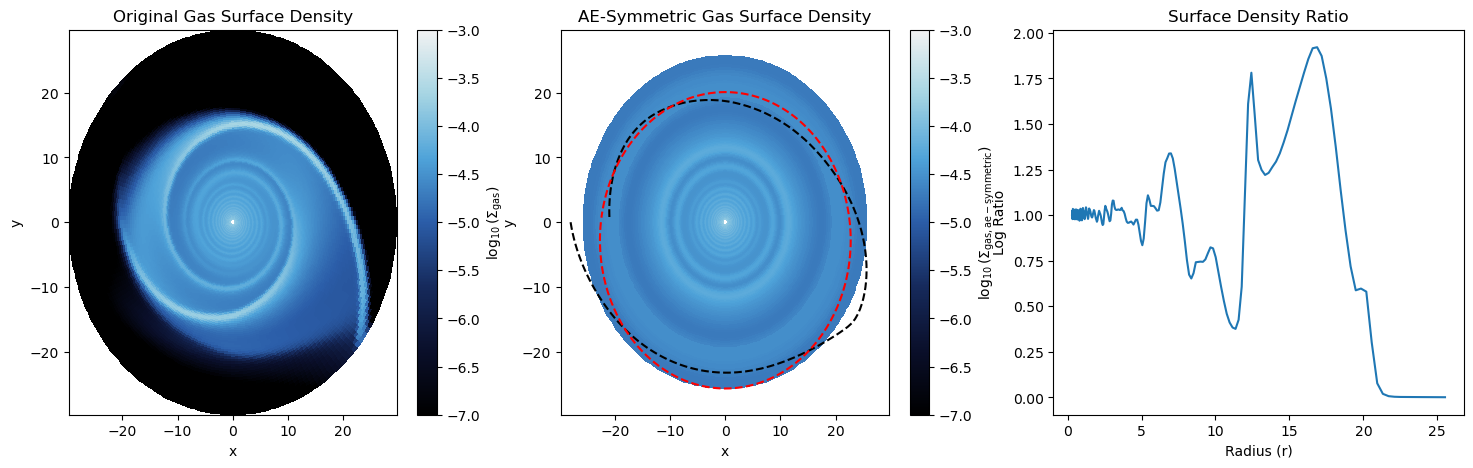

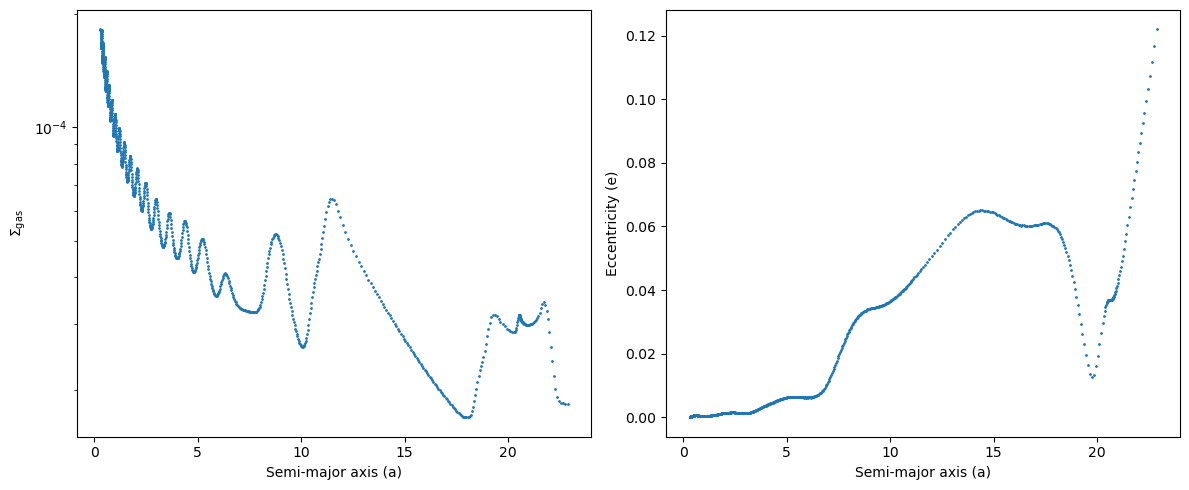

In [12]:

from utils.interpolation import interpolate, interpolate_vectorized
from analysis.orbital import fit_ellipse_polar

def make_ae_symmetric_disk(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)

    r_grid = loader.r_grid
    phi_grid = loader.phi_grid

    r_inits = np.logspace(np.log10(r_grid[0]), np.log10(28), 1000)
    phi_idx = 0

    r_vecs_gas = streamlines.get_streamline_vectorized(r_inits, phi_idx, orbit, 'gas', 1)
    #r_vecs_dust = streamlines.get_streamline_vectorized(r_inits, phi_idx, orbit, 'dust', 1)

    Sigma_gas = loader.load_gasdens(orbit)
    Sigma_gas_interp = interpolate_vectorized(r_vecs_gas, 0, Sigma_gas, r_grid, phi_grid)

    print(r_vecs_gas[-1])

    Sigma_ae_symmetric = np.zeros_like(Sigma_gas)
    counts = np.zeros_like(Sigma_gas)

    a_list = []
    e_list = []
    sigma_list = []

    for i in range(len(r_inits)):
        a, e, varpi = fit_ellipse_polar(r_vecs_gas[i], phi_grid)
        r = a * (1 - e**2) / (1 + e * np.cos(phi_grid - varpi))
        r_idx = np.clip(np.searchsorted(r_grid, r) - 1, 0, len(r_grid) - 1)
        Sigma_mean_interp = np.mean(Sigma_gas_interp[i])
        Sigma_ae_symmetric[r_idx, :] += Sigma_mean_interp
        counts[r_idx, :] += 1

        a_list.append(a)
        e_list.append(e)
        sigma_list.append(Sigma_mean_interp)
    Sigma_ae_symmetric = np.where(counts > 0, Sigma_ae_symmetric / counts, np.nan)

    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    pcm = ax[0].pcolormesh(loader.X, loader.Y, np.log10(Sigma_gas), cmap=cmap, vmin=-7, vmax=-3)
    cm = plt.colorbar(pcm, ax=ax[0], label=r'$\log_{10}(\Sigma_{\rm gas})$')
    ax[0].set_xlabel('x')
    ax[0].set_ylabel('y')
    ax[0].set_title('Original Gas Surface Density')

    pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(Sigma_ae_symmetric), cmap=cmap, vmin=-7, vmax=-3)
    cm = plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas, ae-symmetric})$')
    ax[1].set_xlabel('x')
    ax[1].set_ylabel('y')
    ax[1].set_title('AE-Symmetric Gas Surface Density')
    ax[1].plot(r_vecs_gas[-1] * np.cos(phi_grid), r_vecs_gas[-1] * np.sin(phi_grid), 'k--', label='Streamline')
    r_last = a_list[-1] * (1 - e_list[-1]**2) / (1 + e_list[-1] * np.cos(phi_grid - varpi))
    ax[1].plot(r_last * np.cos(phi_grid), r_last * np.sin(phi_grid), 'r--', label='Fitted Ellipse')

    ax[2].plot(r_grid, Sigma_gas[:, 0] / Sigma_ae_symmetric[:, 0], label='Original')
    ax[2].set_xlabel('Radius (r)')
    ax[2].set_ylabel('Log Ratio')
    ax[2].set_title('Surface Density Ratio')

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].scatter(a_list, sigma_list, s=1)
    ax[0].set_xlabel('Semi-major axis (a)')
    #ax[0].set_ylabel('Eccentricity (e)')
    ax[0].set_ylabel(r'$\Sigma_{\rm gas}$')
    ax[0].set_yscale('log')

    ax[1].scatter(a_list, e_list, s=1)
    ax[1].set_xlabel('Semi-major axis (a)')
    ax[1].set_ylabel('Eccentricity (e)')
    plt.tight_layout()
    plt.show()


path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/'
make_ae_symmetric_disk(path, ORBIT)


particle
Stokes number range: 0.004959859887356251 - 11480859.514407177
106
particle
Stokes number range: 0.04968223870620463 - 114808568.46094644
154
particle
Stokes number range: 0.4999734785799418 - 1148086175.0269914
78
particle
Stokes number range: 4.986471858130613 - 11480857501.677732
176


c:\Users\david\Documents\CircumstellarDisks\fargo\Fargo-Simulations\analysis\stokes.py:214: RuntimeWarning: invalid value encountered in sqrt
  beta      = np.sqrt(1 + 2 * eta)
C:\Users\david\AppData\Local\Temp\ipykernel_32332\1192692115.py:63: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax.pcolormesh(X, Y, np.log10(dustdens), cmap=cmap, vmin = -10, vmax = -6)


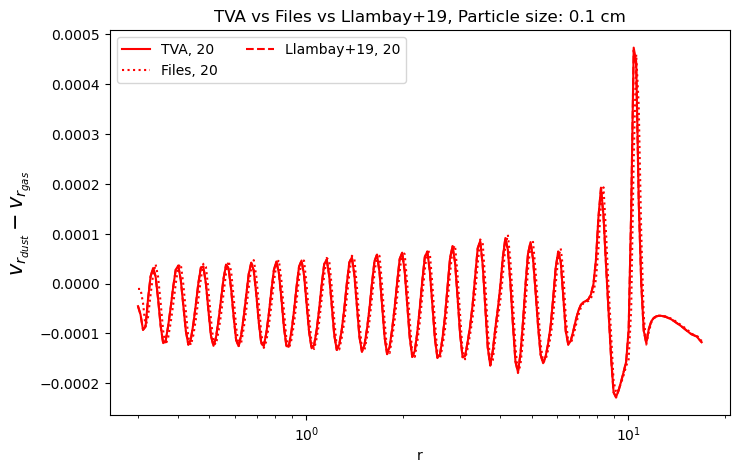

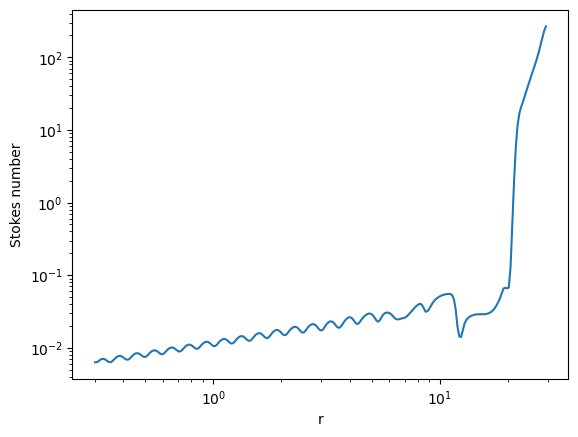

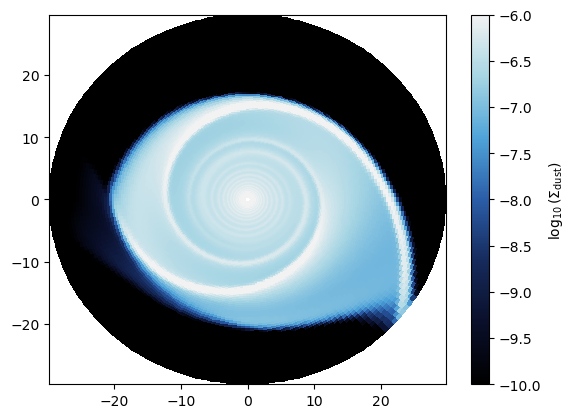

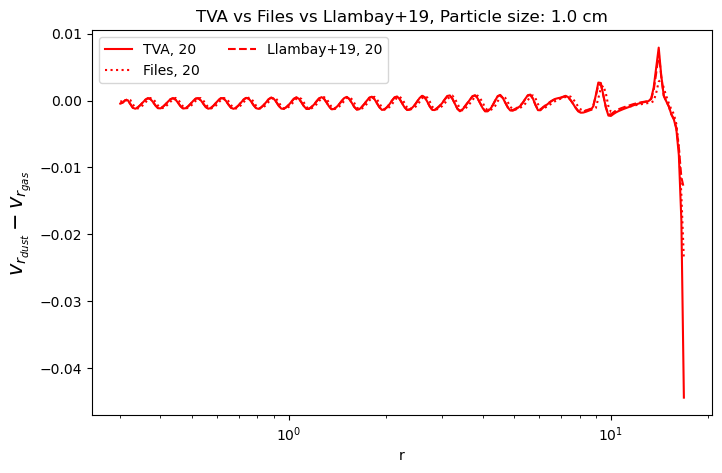

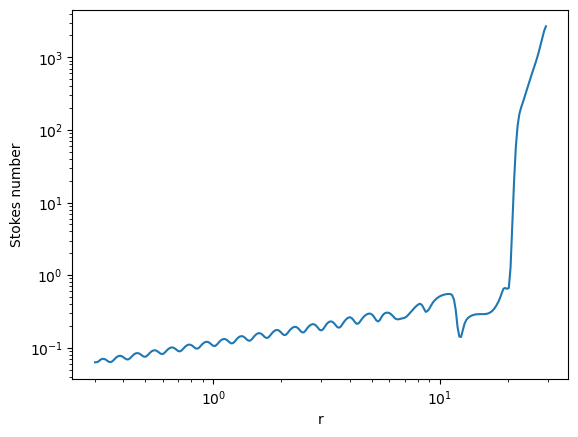

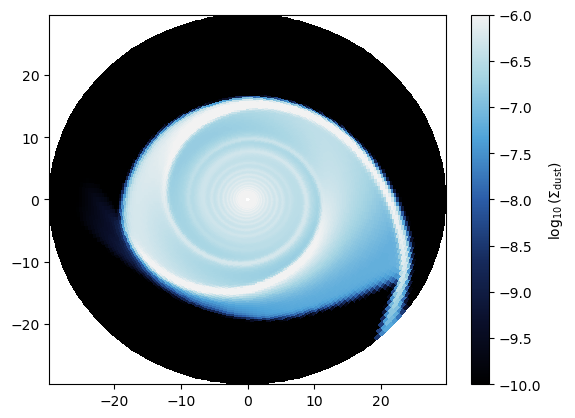

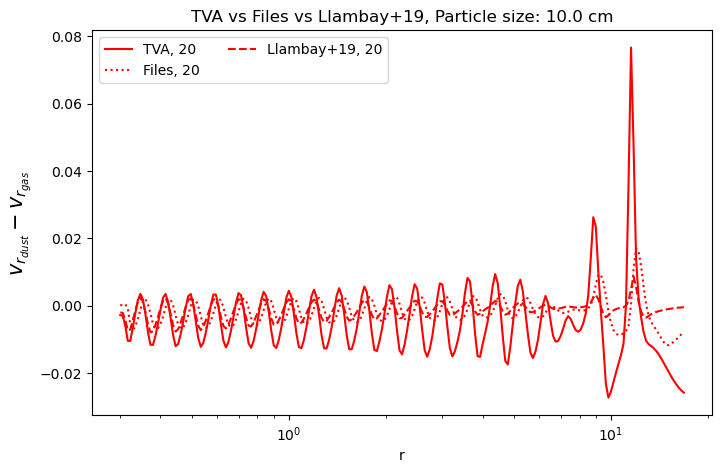

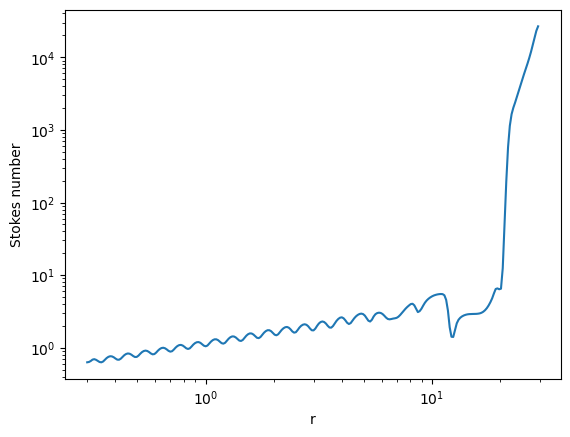

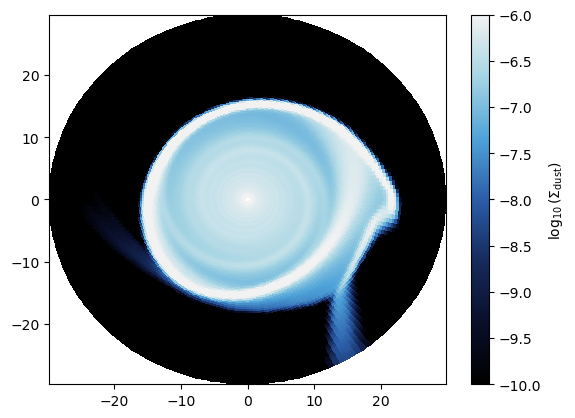

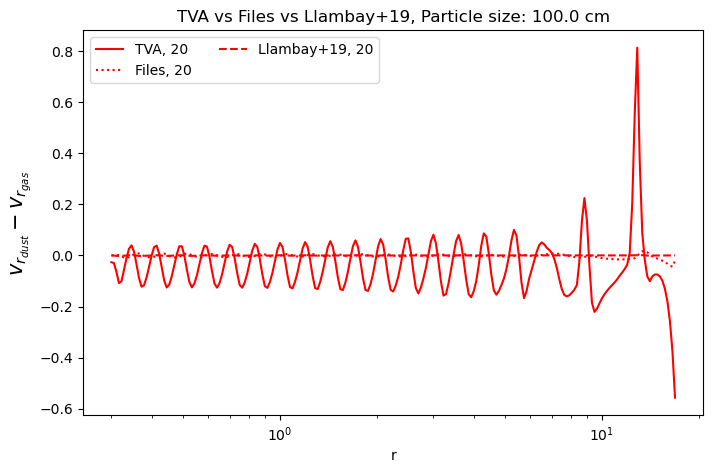

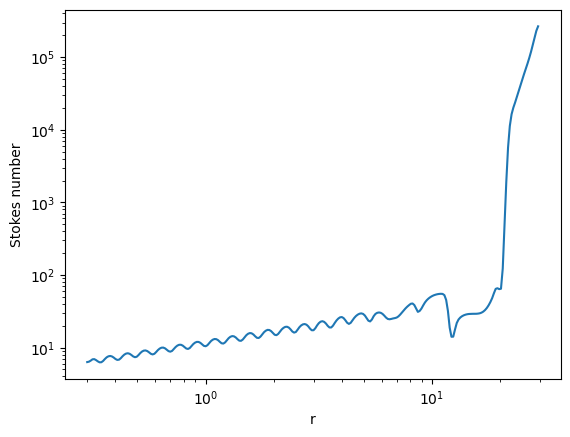

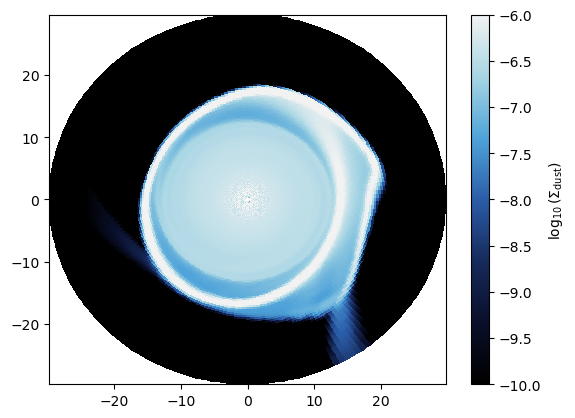

In [38]:
%reload_ext autoreload
%autoreload 2
def relative_vel(path, orbit):
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    rvc = relative_velocity_calculator(loader, variables, streamlines, 1, gastype)

    vr_fargo_sim = rvc.calculate_relative_velocity(orbit)
    print(particle_type)
    
    vr_TVA = rvc.TVA(orbit, path, particle_type)

    vr_llambay, St = rvc.llambay_19(orbit, path, particle_type)

    params = read_par(path)

    #St = 1/float(params['INVSTOKES1'])
    particle_size = float(params['PARTICLESIZE1'])

    

    phi_grid = np.loadtxt(path + 'domain_x.dat')[:-1]
    r_grid = np.loadtxt(path + 'domain_y.dat')[3:-4]
    X, Y = loader.X, loader.Y

    cmap_lines = plt.cm.rainbow

    color = cmap_lines(orbit/20)


    mask = r_grid < 17
    phi_idx = random.randint(0, len(phi_grid) - 1)
    #phi_idx = 75
    print(phi_idx)
    vr_profile = vr_TVA[:, phi_idx]
    vr_sim_profile = vr_fargo_sim[:, phi_idx]
    vr_llambay = vr_llambay[:, phi_idx]

    
    #ax3.plot(r_grid[mask], np.log10(-vr_profile[mask]), color = cmap_lines(orbit/max(orbits)), label=rf'TVA, {orbit}')
    #ax3.plot(r_grid[mask], np.log10(-vr_sim_profile[mask]), ':', color=cmap_lines(orbit/max(orbits)), label=rf'Files, {orbit}')
    #ax3.plot(r_grid[mask], np.log10(-vr_llambay[mask]), '--', color=cmap_lines(orbit/max(orbits)), label=rf'Llambay+19, {orbit}')

    ax3.plot(r_grid[mask], (vr_profile[mask]), color = color, label=rf'TVA, {orbit}')
    ax3.plot(r_grid[mask], (vr_sim_profile[mask]), ':', color=color, label=rf'Files, {orbit}')
    ax3.plot(r_grid[mask], (vr_llambay[mask]), '--', color=color, label=rf'Llambay+19, {orbit}')

    #ax3.plot(r_grid[mask], (vr_llambay[mask]/vr_profile[mask]), '-.', color=color, label=rf'Llambay+19/TVA, {orbit}')
    #ax3.plot(r_grid[mask], 1 / (1 + St[:, phi_idx][mask]**2), ':', color='blue', label=rf'1 / (1 + St^2), {orbit}')
    ax3.set_xlabel('r')
    ax3.set_ylabel(r'$v_{r_{dust}} - v_{r_{gas}}$', fontsize = 15)
    #ax3.set_ylabel(r'$v_{r_{Llambay+19}} / v_{r_{TVA}}$', fontsize = 15)
    #ax3.set_yscale('symlog', linthresh=1e-4)
    ax3.legend(ncol=2, fontsize=10)
    ax3.set_xscale('log')

    ax3.set_title(f'TVA vs Files vs Llambay+19, Particle size: {particle_size} cm')

    fig, ax = plt.subplots()
    dustdens = loader.load_dustdens(orbit, 1)
    gasdens = loader.load_gasdens(orbit)
    pcm = ax.pcolormesh(X, Y, np.log10(dustdens), cmap=cmap, vmin = -10, vmax = -6)
    cm = plt.colorbar(pcm, ax=ax, label=r'$\log_{10}(\Sigma_{\rm dust})$')
    


#Sts = [0.01, 0.1, 1, 10, 100]
gastype = 'normal'
Sts = [0.01]
orbits = np.arange(0, 21, 5)
orbits = np.linspace(0, 5, 5, dtype=int)
orbits = [20]
paths = [#f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_nooutbc_v5/',
         #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_axi_v8/', 
         #'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize_bin/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
         '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_highres/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_St0.001/'
        ]

particles = ['particle', 'particle', 'particle', 'particle']

for i, path in enumerate(paths):
    fig3, ax3 = plt.subplots(1, 1, figsize=(8, 5))
    for orbit in orbits:
        #orbit *= 4
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_single_dust_St{St}_nobin_lowvisc_contd/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_St{St}_nobin_powerlawbc_1d/'
        #path = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_St0.01_eps0.01_v2/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_initial_walpha/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_3dust_bin/'
        #path = f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_final_2d/'
        particle_type = particles[i]
        relative_vel(path, orbit)

C:\Users\david\AppData\Local\Temp\ipykernel_8568\3931514809.py:26: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_8568\3931514809.py:32: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap, vmin=-9, vmax=-5)


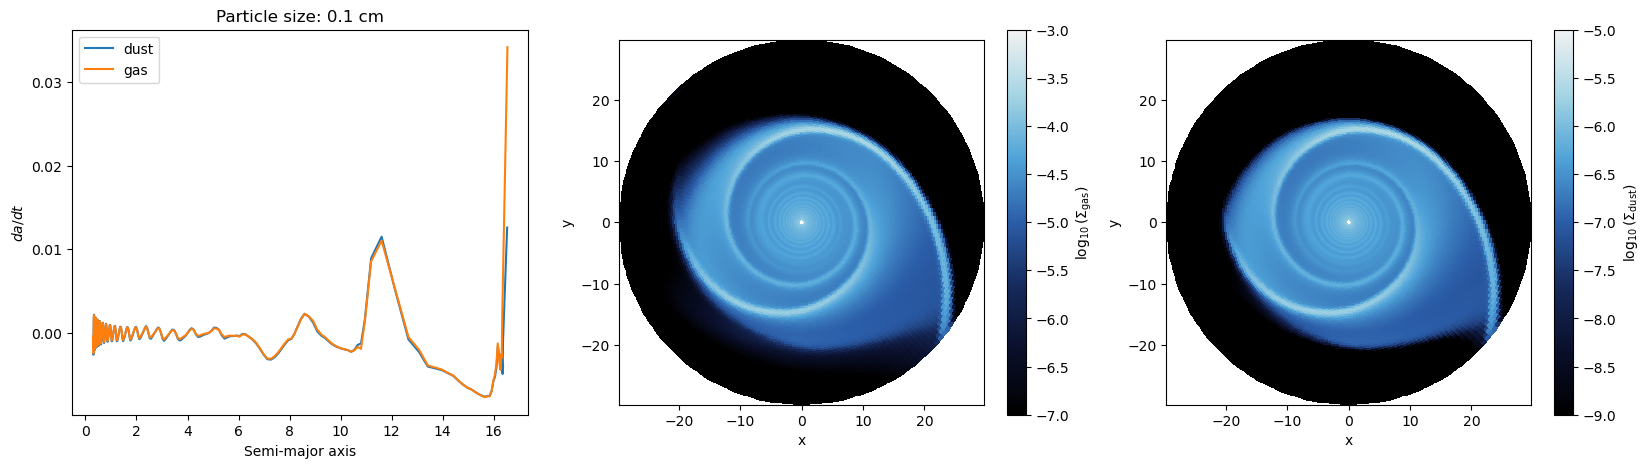

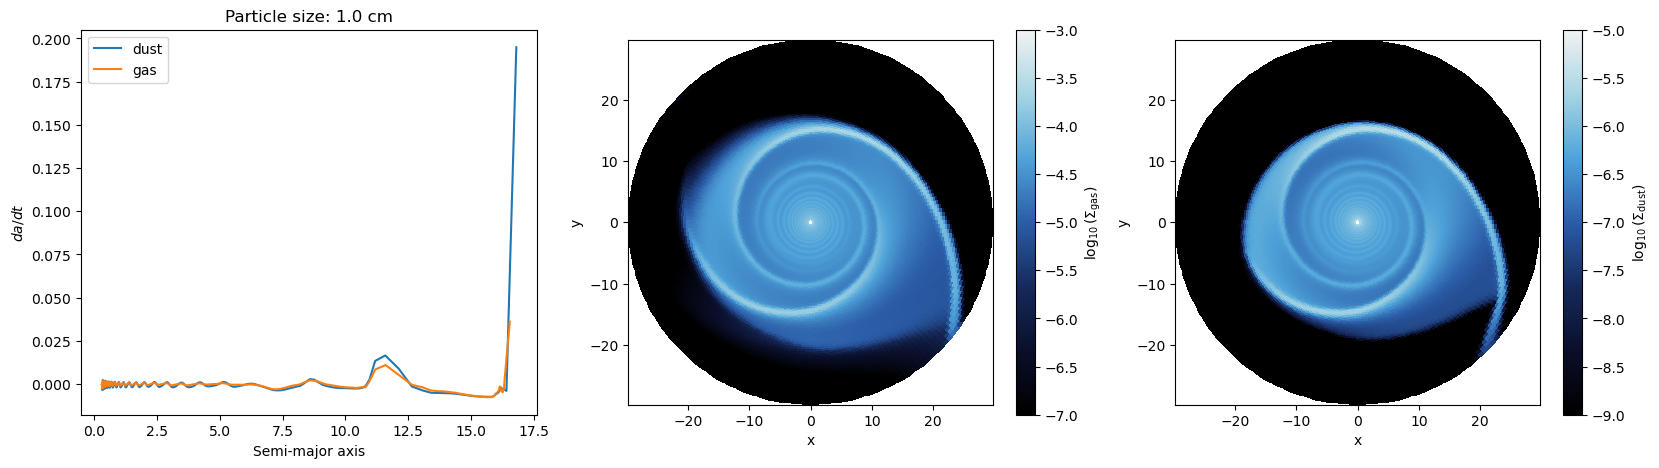

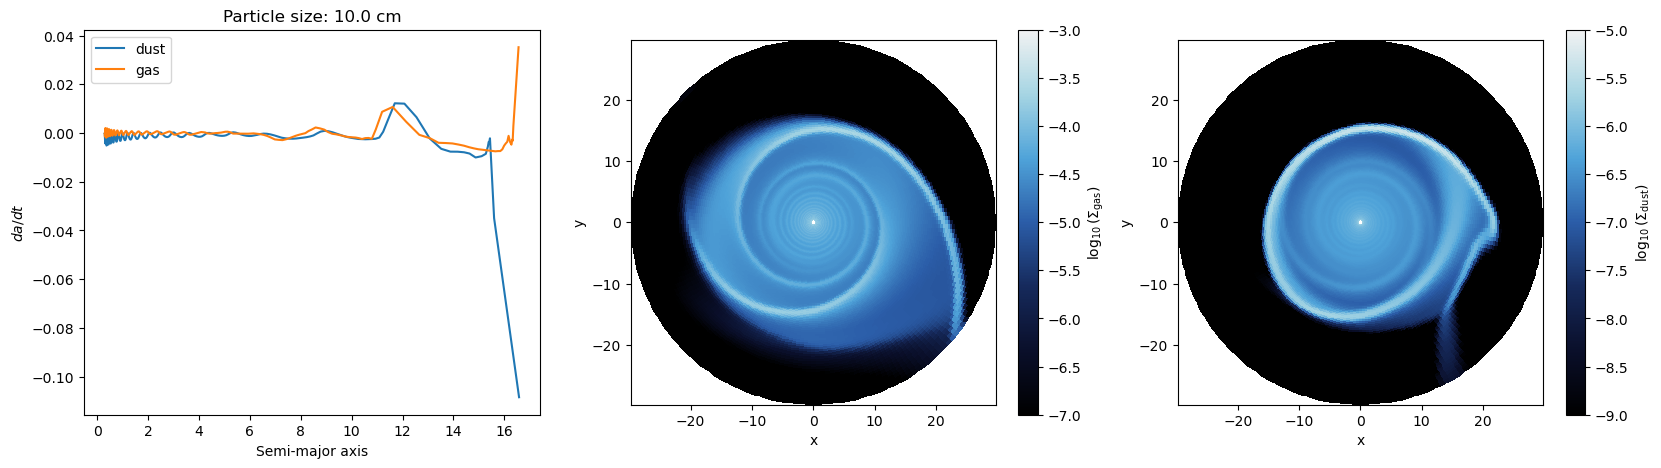

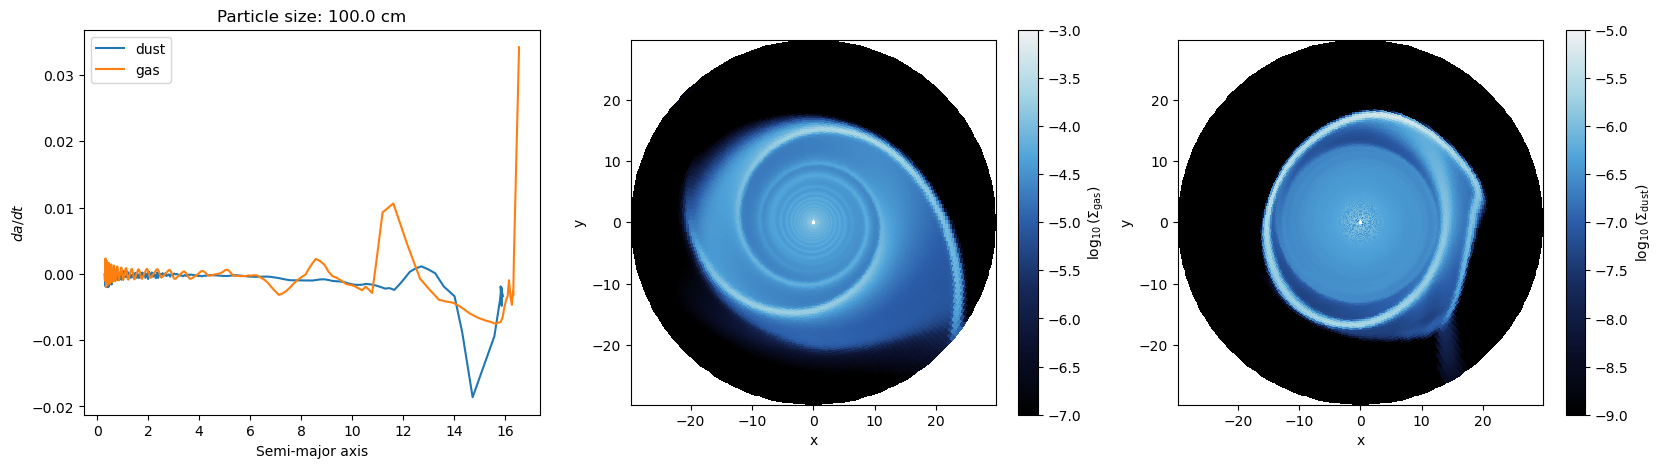

In [ ]:
def plot_da_dt(path, orbit, material, dust_num, ax, cmap):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    a_map, da_dt_map = da_dt.compute_da_dt_TVA(orbit, material)
    mask = a_map[:, 0] < 17
    ax[0].plot(a_map[:, 0][mask], da_dt_map[:, 0][mask], label=rf'{material}')

    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    ax[0].plot(a_array, da_dt_arr, label=rf'{material} (2-stream)')

    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].legend()
    ax[0].set_title(f'Particle size: {particle_size} cm')

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)

        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x')
        ax[1].set_ylabel('y')
        ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap, vmin=-9, vmax=-5)
        plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x')
        ax[2].set_ylabel('y')
        ax[2].set_aspect('equal')


ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']
cmap = 'viridis'  # or whatever you were using before

for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for material in materials:
        plot_da_dt(path, ORBIT, material, dust_num, ax, cmap)

C:\Users\david\AppData\Local\Temp\ipykernel_32332\2241160528.py:51: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_32332\2241160528.py:57: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)


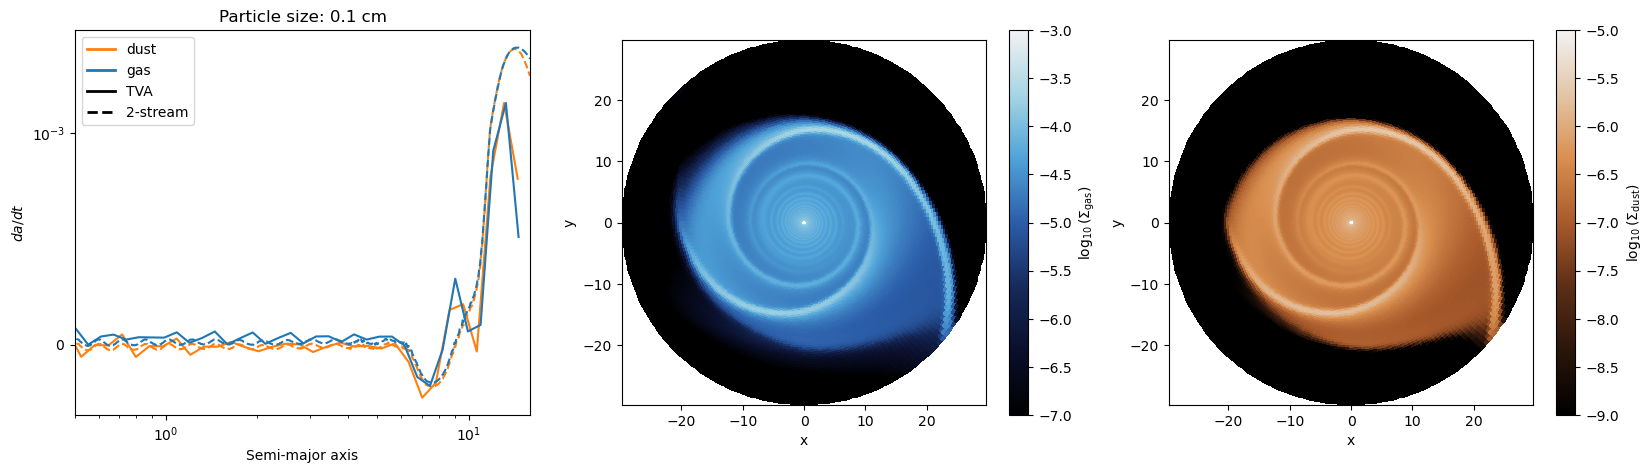

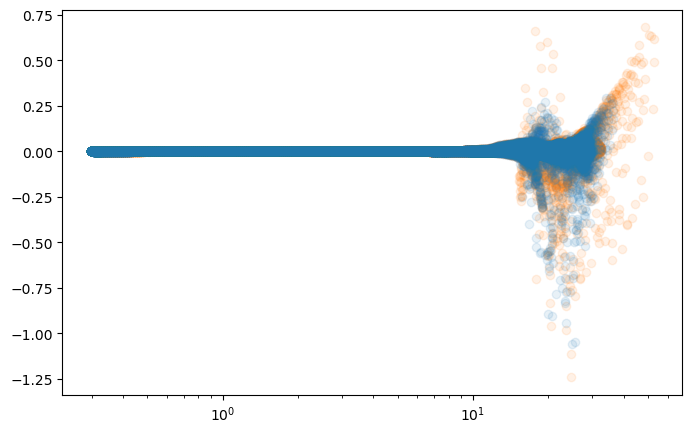

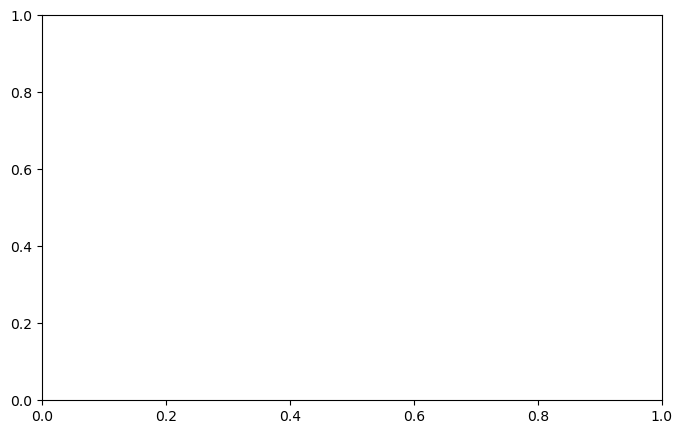

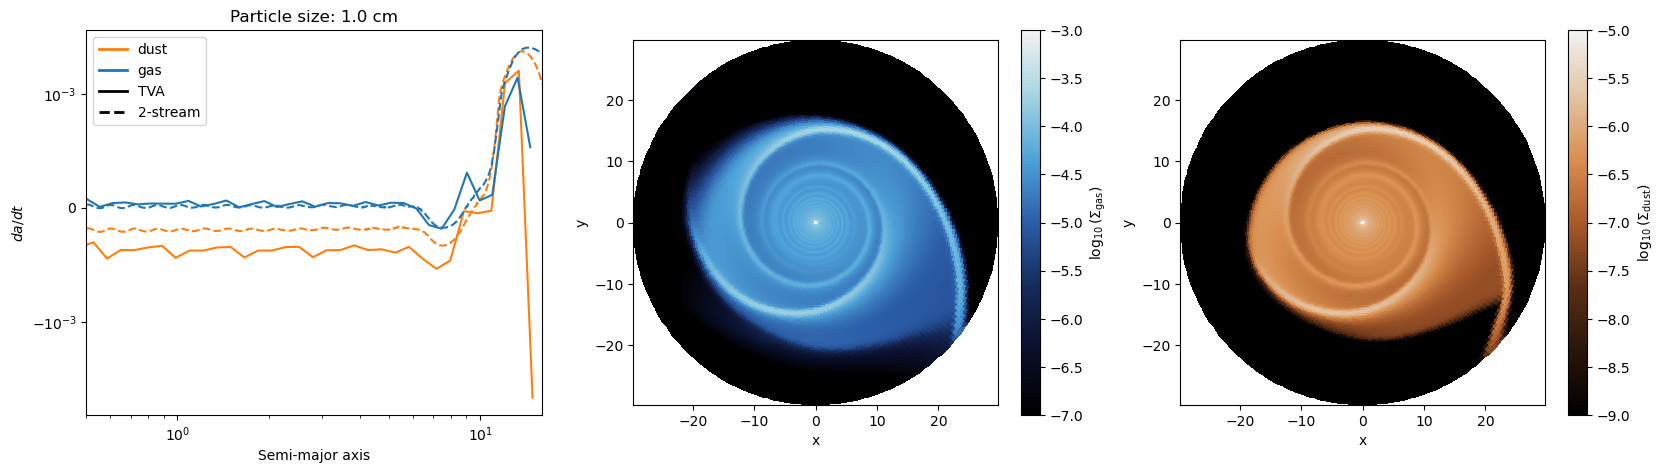

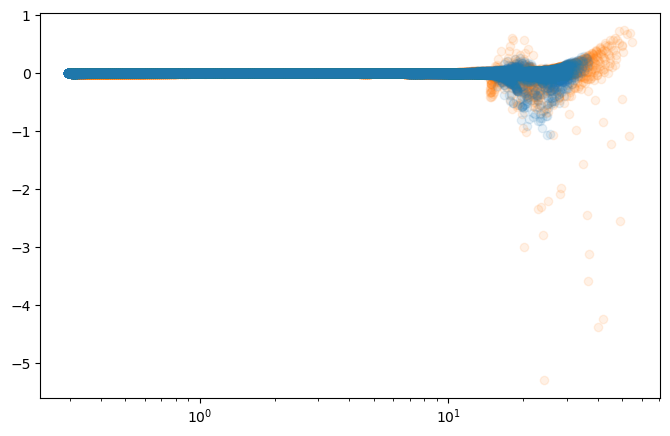

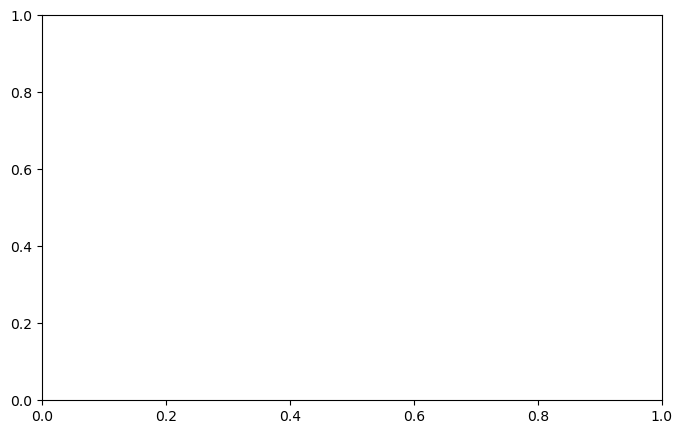

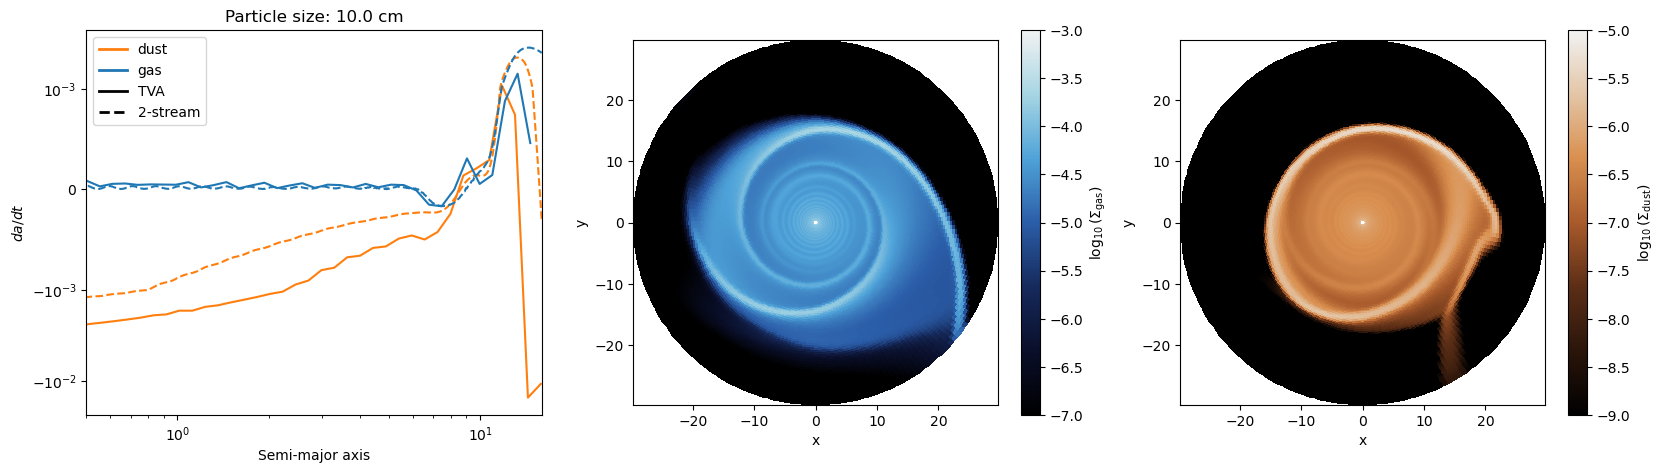

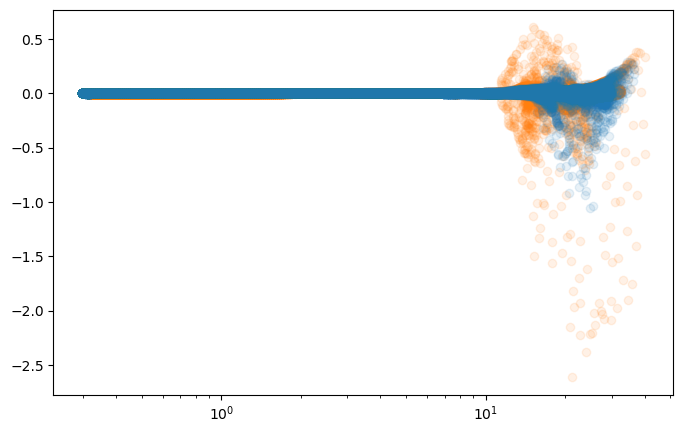

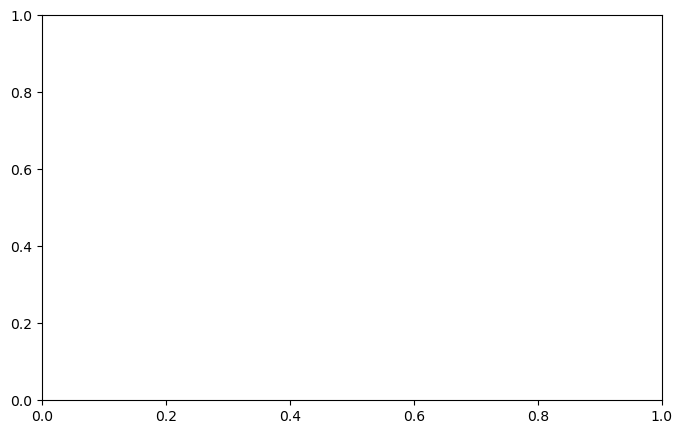

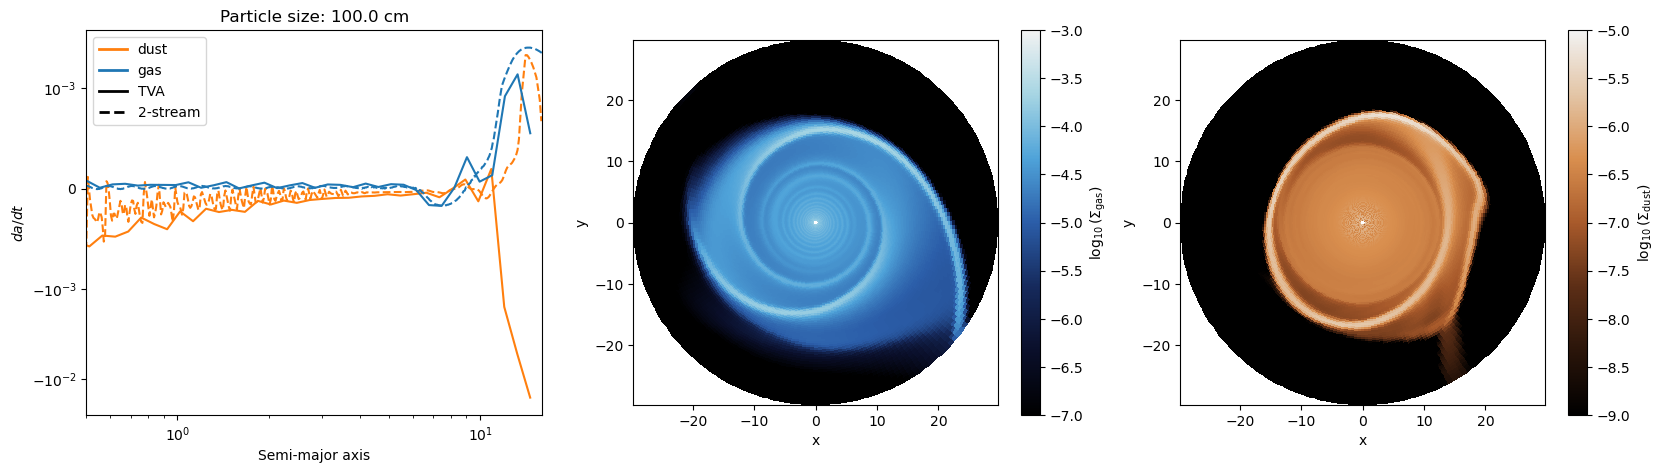

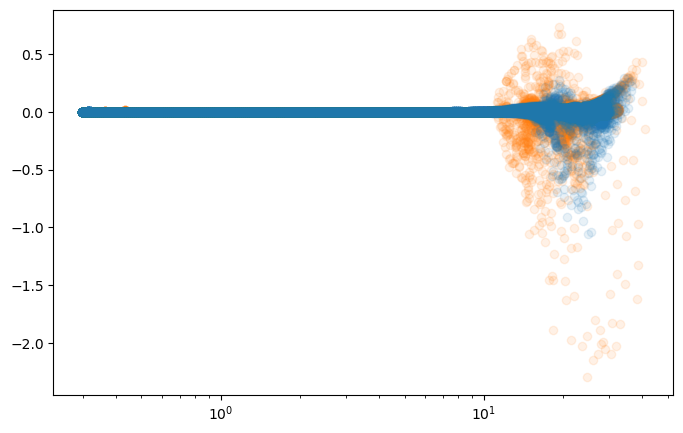

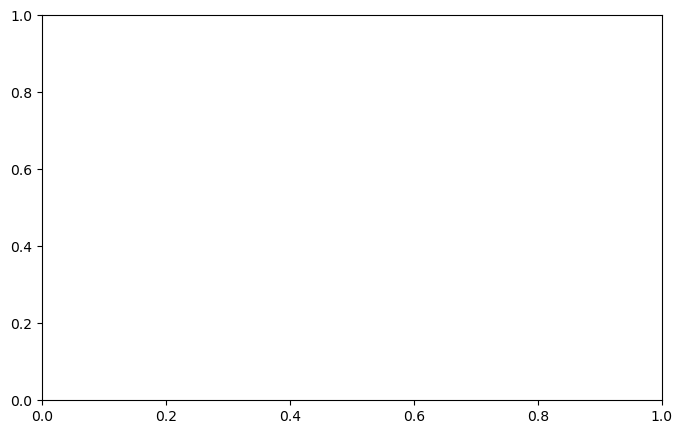

In [ ]:
%reload_ext autoreload
%autoreload 2

from scipy.stats import binned_statistic
COLORS = {'dust': 'tab:orange', 'gas': 'tab:blue'}
LINESTYLES = {'TVA': '-', '2-stream': '--'}


def plot_da_dt(path, orbit, material, dust_num, ax):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)

    color = COLORS[material]

    a_map, da_dt_map = da_dt.compute_da_dt_TVA(orbit, material)
    a_flat = a_map.flatten()
    ax1.scatter(a_flat, da_dt_map.flatten(), color=color, alpha=0.1, label=f'{material} (TVA)')
    ax1.set_xscale('log')
    #ax1.set_xlim(0, 1)
    da_dt_flat = da_dt_map.flatten()
    n_bins = 50
    bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
    da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
    da_dt_std, _, _ = binned_statistic(a_flat, da_dt_flat, statistic='std', bins=bin_edges)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    mask = bin_centers < 16
    ax[0].plot(bin_centers[mask], da_dt_mean[mask],
               color=color, linestyle=LINESTYLES['TVA'])

    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    mask = a_array < 16
    ax[0].plot(a_array[mask], da_dt_arr[mask],
               color=color, linestyle=LINESTYLES['2-stream'])

    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_title(f'Particle size: {particle_size} cm')
    ax[0].set_xscale('log')
    ax[0].set_yscale('symlog', linthresh=1e-3)
    ax[0].set_xlim(0.5, 16)

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)

        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x')
        ax[1].set_ylabel('y')
        ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
        plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x')
        ax[2].set_ylabel('y')
        ax[2].set_aspect('equal')


def add_da_dt_legend(ax):
    """Custom legend: color = material, linestyle = method."""
    from matplotlib.lines import Line2D
    handles = (
        [Line2D([0], [0], color=c, lw=2, label=m) for m, c in COLORS.items()] +
        [Line2D([0], [0], color='black', linestyle=ls, lw=2, label=method)
         for method, ls in LINESTYLES.items()]
    )
    ax.legend(handles=handles)

PATH = '/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_nooutbc_v5/'

paths = [f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize0.1/', 
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize1/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize10/',
        f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dustsize100/',
        #f'/Users/david/Documents/CircumstellarDisks/fargo/fargo_dustydisk_1dust_bin_St0.001/'
        ]

ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']


for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig1, ax1 = plt.subplots(1, 1, figsize=(8, 5))
    for material in materials:
        plot_da_dt(path, ORBIT, material, dust_num, ax)
    add_da_dt_legend(ax[0])

starting computation for dust drag
number of negative a values (drag): 1704
starting computation for dust sim
number of negative a values (sim): 0
starting 2-stream computation for dust
starting computation for gas drag
number of negative a values (drag): 0
starting computation for gas sim
number of negative a values (sim): 0
starting 2-stream computation for gas


C:\Users\david\AppData\Local\Temp\ipykernel_32332\2294744449.py:53: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
C:\Users\david\AppData\Local\Temp\ipykernel_32332\2294744449.py:57: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)


starting computation for dust drag
number of negative a values (drag): 1852
starting computation for dust sim
number of negative a values (sim): 0
starting 2-stream computation for dust
starting computation for gas drag
number of negative a values (drag): 0
starting computation for gas sim
number of negative a values (sim): 0
starting 2-stream computation for gas
starting computation for dust drag
number of negative a values (drag): 2003
starting computation for dust sim
number of negative a values (sim): 0
starting 2-stream computation for dust
starting computation for gas drag
number of negative a values (drag): 0
starting computation for gas sim
number of negative a values (sim): 0
starting 2-stream computation for gas
starting computation for dust drag
number of negative a values (drag): 2195
starting computation for dust sim
number of negative a values (sim): 0
starting 2-stream computation for dust
starting computation for gas drag
number of negative a values (drag): 0
starting c

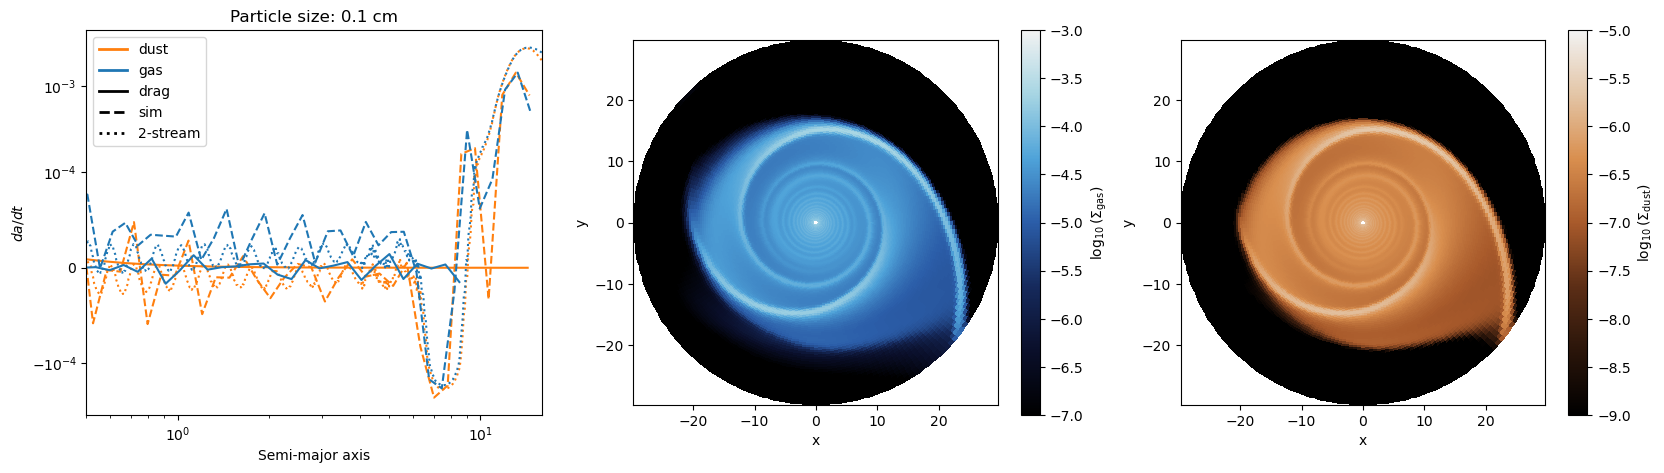

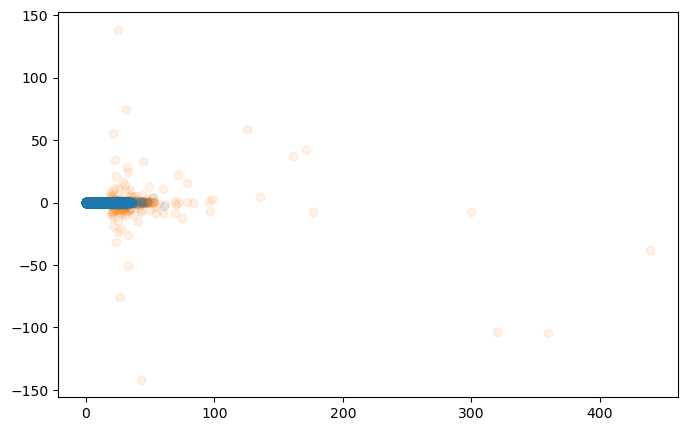

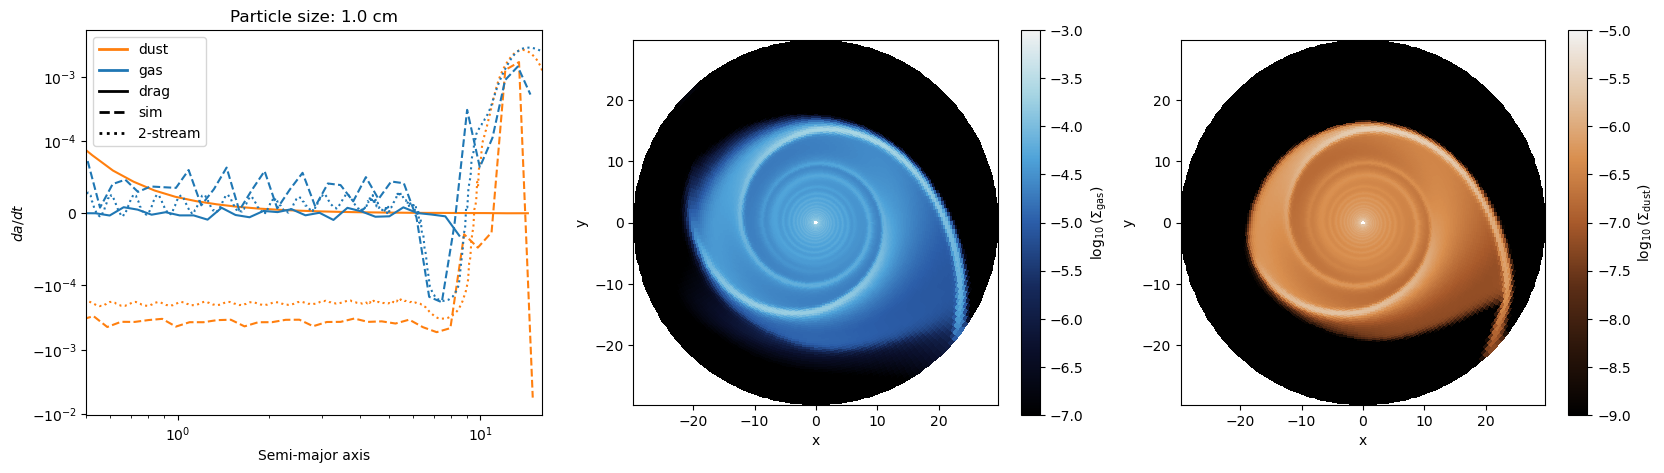

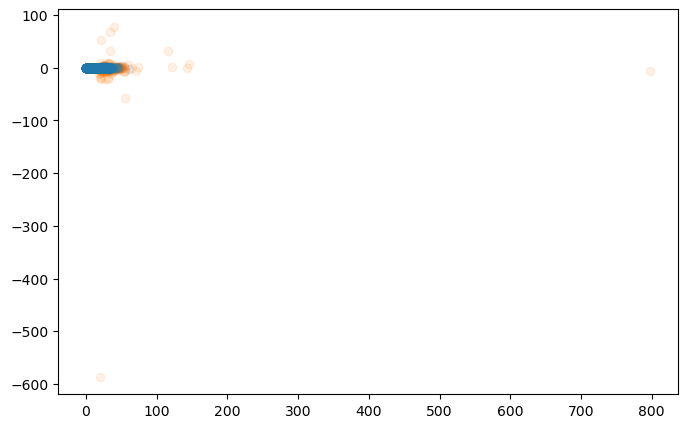

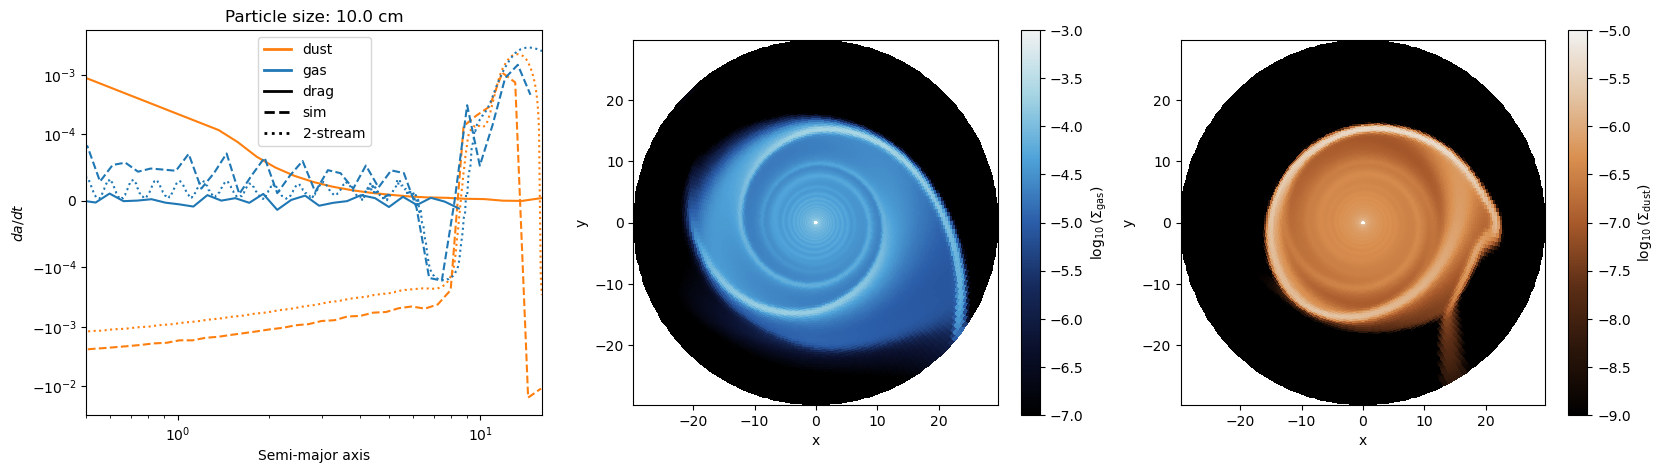

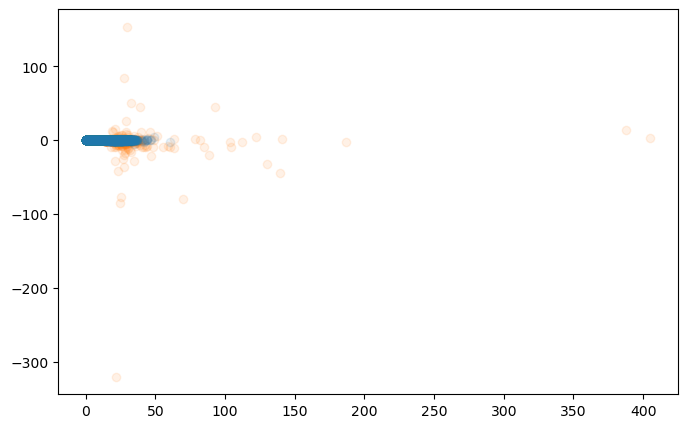

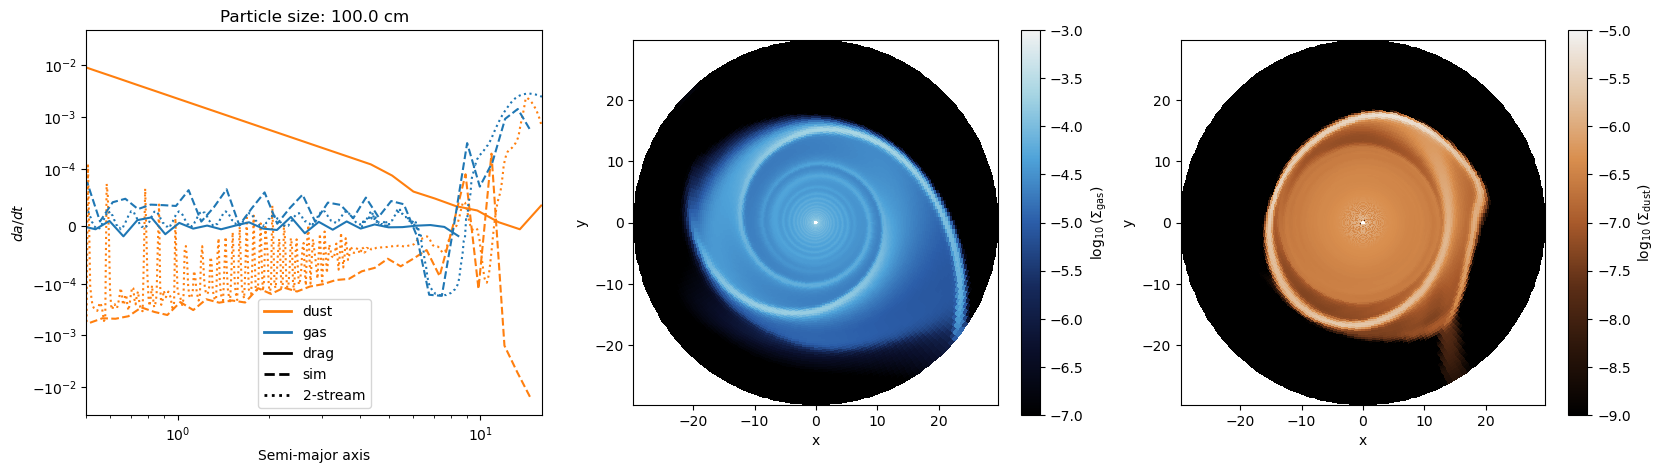

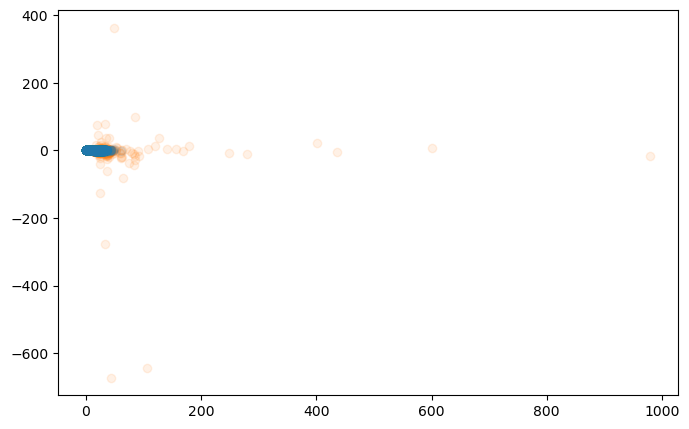

In [66]:
LINESTYLES = {'drag': '-', 'sim': '--', '2-stream': ':'}

def plot_da_dt(path, orbit, material, dust_num, methods, ax, ax1):
    params = read_par(path)
    particle_size = float(params[f'PARTICLESIZE{dust_num}'])
    loader = SimulationDataLoader(path)
    variables = SimulationVariablesCalculator(loader)
    streamlines = SimulationDataStreamlines(loader, variables)
    da_dt = da_dt_calculator(loader, variables, streamlines, dust_num)
    color = COLORS[material]

    for method in methods:
        print('starting computation for', material, method)
        a_map, da_dt_map = da_dt.compute_da_dt_TVA(orbit, material, method=method)

        a_flat = a_map.flatten()
        print(f'number of negative a values ({method}): {(a_flat < 0).sum()}')
        mask = a_flat > 0
        a_flat = a_flat[mask]
        da_dt_flat = da_dt_map.flatten()[mask]

        if a_flat.size == 0:
            print(f'no positive a values for {material}/{method}, skipping')
            continue

        ax1.scatter(a_flat, da_dt_flat, color=color, alpha=0.1, label=f'{material} ({method})')

        n_bins = 50
        bin_edges = np.logspace(np.log10(a_flat.min()), np.log10(a_flat.max()), n_bins + 1)
        da_dt_mean, bin_edges, _ = binned_statistic(a_flat, da_dt_flat, statistic='mean', bins=bin_edges)
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

        bmask = bin_centers < 16
        ax[0].plot(bin_centers[bmask], da_dt_mean[bmask], color=color, linestyle=LINESTYLES[method])

    # 2-stream computed once per material, not once per method
    print('starting 2-stream computation for', material)
    a_array, da_dt_arr = da_dt.compute_da_dt_2streams(path, orbit, material)
    smask = (a_array > 0) & (a_array < 16)
    ax[0].plot(a_array[smask], da_dt_arr[smask], color=color, linestyle=LINESTYLES['2-stream'])

    ax[0].set_xlabel('Semi-major axis')
    ax[0].set_ylabel(r'$da/dt$')
    ax[0].set_title(f'Particle size: {particle_size} cm')
    ax[0].set_xscale('log')
    ax[0].set_yscale('symlog', linthresh=1e-4)
    ax[0].set_xlim(0.5, 16)

    if material == 'gas':
        gasdens = loader.load_gasdens(orbit)
        dust_dens = loader.load_dustdens(orbit, dust_num)

        pcm = ax[1].pcolormesh(loader.X, loader.Y, np.log10(gasdens), cmap=cmap, vmin=-7, vmax=-3)
        plt.colorbar(pcm, ax=ax[1], label=r'$\log_{10}(\Sigma_{\rm gas})$')
        ax[1].set_xlabel('x'); ax[1].set_ylabel('y'); ax[1].set_aspect('equal')

        pcm = ax[2].pcolormesh(loader.X, loader.Y, np.log10(dust_dens), cmap=cmap_dust, vmin=-9, vmax=-5)
        plt.colorbar(pcm, ax=ax[2], label=r'$\log_{10}(\Sigma_{\rm dust})$')
        ax[2].set_xlabel('x'); ax[2].set_ylabel('y'); ax[2].set_aspect('equal')


def add_da_dt_legend(ax):
    from matplotlib.lines import Line2D
    handles = (
        [Line2D([0], [0], color=c, lw=2, label=m) for m, c in COLORS.items()] +
        [Line2D([0], [0], color='black', linestyle=ls, lw=2, label=lbl)
         for lbl, ls in LINESTYLES.items()]
    )
    ax.legend(handles=handles)


ORBIT = 20
dust_num = 1
materials = ['dust', 'gas']
methods = ['drag', 'sim']

for path in paths:
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    fig1, ax1 = plt.subplots(1, 1, figsize=(8, 5))
    for material in materials:
        plot_da_dt(path, ORBIT, material, dust_num, methods, ax, ax1)
    add_da_dt_legend(ax[0])